In [1]:
import sys
sys.path.append('/home/users/lucalino/')
import numpy as np
import xarray as xr
import pandas as pd
from utils import *
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
from matplotlib.colors import BoundaryNorm
import cartopy.crs as ccrs
from scipy.stats import pearsonr
import seaborn as sns

In [ ]:
secperday = 24*60*60
land_thres = 0.5
fs = 18
derivatives_folder = '/gws/ssde/j25b/global_ex/lms47/data/era5_derivatives/'
figure_folder = '/home/users/lucalino/research/hot_day_moisture_budget/figures/paper/'

extreme_var = 't2m'
epsilon = 0.0
lead_time_window_dq = slice(-4,-1) # time window over which to calculate mean drying/moistening - final decision
plot_start = -16
plot_end = 6
dq_crit = 'tcwv'
composite_folder = f'{extreme_var}_composites/'

var_colors = {
    'T' : 'brown',
    'TCWV' : 'tab:blue',
    'CONV' : 'tab:purple',
    'P' : 'tab:orange',
    'ET' : 'tab:green',
}

In [3]:
aridity_levels_names = ['moist', 'semi-moist', 'semi-arid', 'arid']
aridity_linestyle = ['solid', 'dashdot', 'dashed', 'dotted']

ai_palette = {
    'moist': plt.cm.tab20b(1),
    'semi-moist': plt.cm.tab20b(5),
    'semi-arid': plt.cm.tab20b(9),
    'arid': plt.cm.tab20b(13)
}

In [4]:
# load extreme data
dex = xr.open_zarr(derivatives_folder + 'era5_hot_day_full_col_mb_components_extreme_var=t2m_region=tropics.zarr', 
                     chunks={},
                     consolidated=True,
                     )
dex = dex.assign(lsm = xr.open_dataarray(derivatives_folder + 'era5_land_sea_mask_region=tropics.nc'))
dex = dex.assign(ai_percentile = xr.open_dataarray(derivatives_folder + 'era5_ai_percentiles_region=tropics.nc'))


# Correlation between tcwv and q2m

In [5]:
# stack relevant data
ds = dex[['tcwv', 'q2m']].sel(lead_time=slice(-12,2)).where(dex.lsm > land_thres).stack(new_dim = ('year', 'lead_time', 'latitude', 'longitude')).dropna('new_dim')
ds

<xarray.Dataset> Size: 2GB
Dimensions:    (new_dim: 35905980)
Coordinates:
  * new_dim    (new_dim) object 287MB MultiIndex
    time       (new_dim) datetime64[ns] 287MB dask.array<chunksize=(46368,), meta=np.ndarray>
  * year       (new_dim) int64 287MB 1980 1980 1980 1980 ... 2023 2023 2023 2023
  * lead_time  (new_dim) int64 287MB -12 -12 -12 -12 -12 -12 -12 ... 2 2 2 2 2 2
  * latitude   (new_dim) float32 144MB 20.0 20.0 20.0 20.0 ... -20.0 -20.0 -20.0
  * longitude  (new_dim) float32 144MB 0.0 0.25 0.5 0.75 ... 319.2 319.5 319.8
Data variables:
    tcwv       (new_dim) float32 144MB dask.array<chunksize=(46368,), meta=np.ndarray>
    q2m        (new_dim) float32 144MB dask.array<chunksize=(46368,), meta=np.ndarray>
Attributes:
    acknowledgment:    Contains Copernicus Climate Change Service information...
    contact:           lms47@st-andrews.ac.uk
    creator:           Luca Schmidt
    description:       Hot day full column moisture budget components
    source:            The dataset is based on ERA5 reanalysis data and conta...
    valid_time_start:  1980-01-01
    valid_time_stop:   2023-12-31

In [6]:
pearsonr(ds.tcwv.values, ds.q2m.values)

PearsonRResult(statistic=np.float32(0.89385605), pvalue=np.float32(0.0))

# Quantification of ice and liquid water convergence relative to total moisture convergence

In [31]:
w = np.cos(np.deg2rad(dex.latitude))          # area weights
land = dex.lsm > land_thres
cond  = dex.vilw.where(land) + dex.viiw.where(land) # condensate divergence
mvimd = dex.mvimd.where(land) # total divergence of moisture
dims  = ['year', 'lead_time']


# 1. Composite mean: the quantity that actually enters your hot-day budget
c_bar, m_bar = cond.mean(dims).compute(), mvimd.mean(dims).compute()
ratio_comp = abs(c_bar).weighted(w).mean() / abs(m_bar).weighted(w).mean()

# 2. Typical size of individual events (RMS over all hot days and gridpoints)
rms = lambda x: np.sqrt((x**2).weighted(w).mean())
ratio_rms = rms(cond) / rms(mvimd)

# 3. Spatial distribution of the composite ratio, ignoring tiny denominators
thr = abs(m_bar).quantile(0.1)                # or a physical threshold
r = (abs(c_bar) / abs(m_bar)).where(abs(m_bar) > thr)
r_q = r.quantile([0.5, 0.9, 0.99], dim=['latitude', 'longitude'])

print(float(ratio_comp), float(ratio_rms), r_q.values)

0.04487663879990578 0.03945364058017731 [0.0324406  0.20195123 0.83520645]


# Aridity index percentile map (Figure 1d)

In [5]:
# create colormap with 4 distinct colors for the four different AI percentile ranges
colors = [plt.cm.tab20b(12), plt.cm.tab20b(13), plt.cm.tab20b(14), plt.cm.tab20b(15),
          plt.cm.tab20b(8), plt.cm.tab20b(9), plt.cm.tab20b(10), plt.cm.tab20b(11),
          plt.cm.tab20b(7), plt.cm.tab20b(6), plt.cm.tab20b(5), plt.cm.tab20b(4),
          plt.cm.tab20b(3), plt.cm.tab20b(2), plt.cm.tab20b(1), plt.cm.tab20b(0)]
cmap=mcolors.ListedColormap(colors)

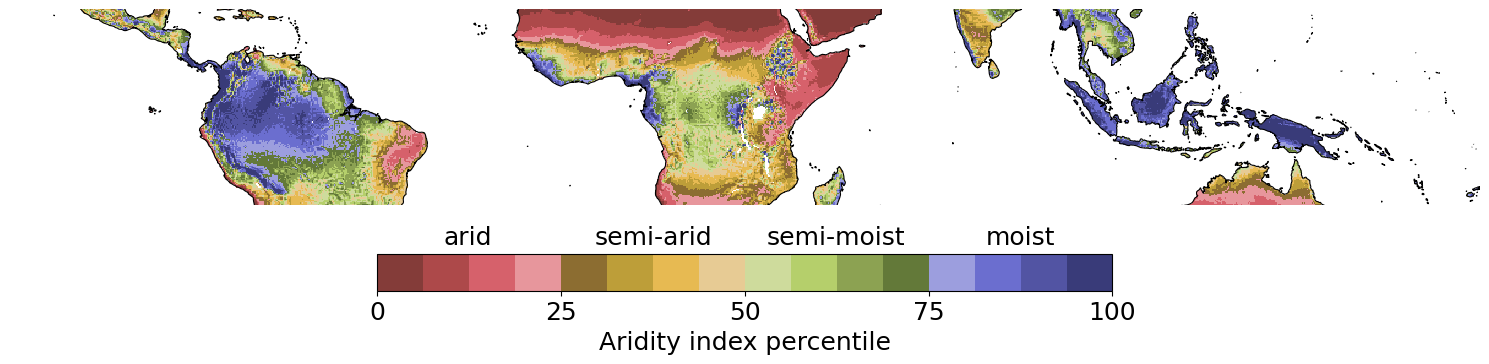

In [ ]:
fig, ax = plt.subplots(figsize=(15, 4), subplot_kw={"projection": ccrs.PlateCarree()})
ax.coastlines(lw=0.8)
ax.set_extent([-150, 180, -20, 20], crs=ccrs.PlateCarree())
dex.ai_percentile.plot(ax=ax, cmap = cmap, cbar_kwargs={"location": "bottom", "shrink": 0.5})
# Access colorbar from figure
cbar = fig.axes[-1]  # Last axis is usually the colorbar
cbar.set_xlabel("Aridity index percentile", fontsize=fs)
cbar.tick_params(labelsize=fs)
cbar.set_xticks([0, 25, 50, 75, 100])
cbar.set_xticklabels(['0', '25', '50', '75', '100'])
cbar.text(0.09, 1.25, "arid", transform=cbar.transAxes, fontsize=fs)
cbar.text(0.295, 1.25, "semi-arid", transform=cbar.transAxes, fontsize=fs)
cbar.text(0.53, 1.25, "semi-moist", transform=cbar.transAxes, fontsize=fs)
cbar.text(0.828, 1.25, "moist", transform=cbar.transAxes, fontsize=fs)
ax.text(0.014, 0.80, 'd)', transform=ax.transAxes,
        fontsize=fs, ha='left', va='bottom')
ax.set_title("")
plt.tight_layout()
#plt.savefig('/home/users/lucalino/research/hot_day_moisture_budget/figures/paper/era5_aridity_index_map.png', dpi=300)

#

# Composite temperature evolution: dq threshold determination

In [5]:
# aridity categories
arid = (dex.ai_percentile >= 0) & (dex.ai_percentile < 25)
semi_arid = (dex.ai_percentile >= 25) & (dex.ai_percentile < 50)
semi_moist = (dex.ai_percentile >= 50) & (dex.ai_percentile < 75)
moist = (dex.ai_percentile >= 75) & (dex.ai_percentile <= 100)
land = dex.lsm > land_thres
ocean = dex.lsm < land_thres

In [6]:
# load composite timeseries for all events (no moistening/drying distinction)
dmoist = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_all_events.nc')
dsemimoist = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_all_events.nc')
dsemiarid = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_all_events.nc')
darid = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_all_events.nc')  
ocean = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_docean_all_events.nc')

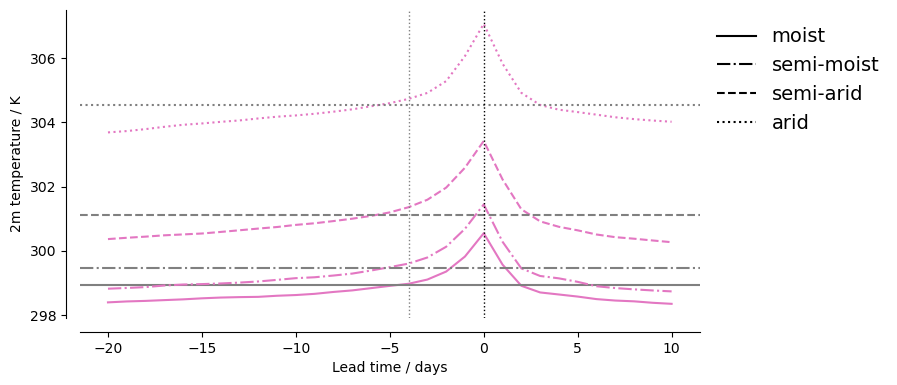

In [8]:
legend_handles = [Line2D([0], [0], color='k', linestyle=ls, label=label) for ls, label in zip(aridity_linestyle, aridity_levels_names)]
time_slice = slice(-20, 10)

fig, ax = plt.subplots(figsize=(8,4))
for i, (data, label, style) in enumerate(zip(
    [dmoist.sel(lead_time = time_slice), dsemimoist.sel(lead_time = time_slice), dsemiarid.sel(lead_time = time_slice), darid.sel(lead_time = time_slice)],
    aridity_levels_names,
    aridity_linestyle
)):
    dt25 = data.t2m.sel(lead_time=-20) + 0.25 * (data.t2m.sel(lead_time=0) - data.t2m.sel(lead_time=-20))
    ax.plot(data.lead_time, data['t2m'], linestyle=style, color='tab:pink', label=label)
    ax.axhline(dt25, color='gray', linestyle=style)
ax.legend(legend_handles, aridity_levels_names, frameon=False,fontsize = fs-4, loc='upper left', bbox_to_anchor=(1, 1), bbox_transform=ax.transAxes)
ax.axvline(0, color='k', linestyle=':', linewidth=1)
ax.axvline(-4, color='gray', linestyle =':', linewidth=1)
ax.set_xlabel('Lead time / days')
ax.set_ylabel('2m temperature / K')
sns.despine(offset=10)

In [9]:
dmoist_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_all_events_doy_clim_comparison.nc')
dsemimoist_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_all_events_doy_clim_comparison.nc')
dsemiarid_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_all_events_doy_clim_comparison.nc')
darid_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_all_events_doy_clim_comparison.nc')  

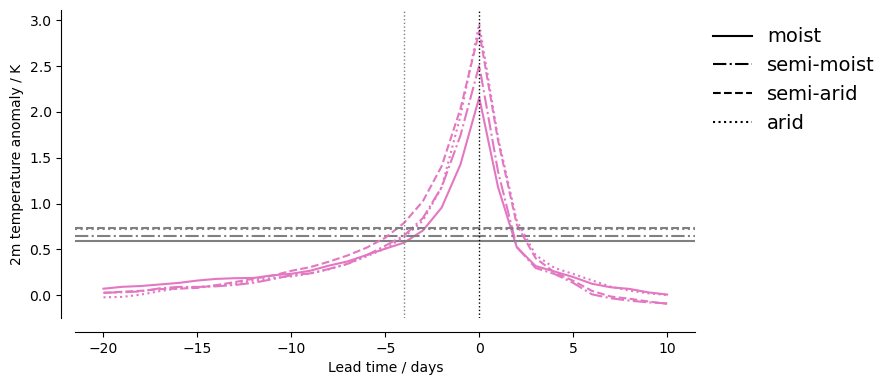

In [12]:
legend_handles = [Line2D([0], [0], color='k', linestyle=ls, label=label) for ls, label in zip(aridity_linestyle, aridity_levels_names)]
time_slice = slice(-20, 10)

fig, ax = plt.subplots(figsize=(8,4))
for i, (data, label, style) in enumerate(zip(
    [dmoist_clim.sel(lead_time = time_slice), dsemimoist_clim.sel(lead_time = time_slice), dsemiarid_clim.sel(lead_time = time_slice), darid_clim.sel(lead_time = time_slice)],
    aridity_levels_names,
    aridity_linestyle
)):
    dt20 = data.t2m_diff_clim_abs.sel(lead_time=-20) + 0.25 * (data.t2m_diff_clim_abs.sel(lead_time=0) - data.t2m_diff_clim_abs.sel(lead_time=-20))
    ax.plot(data.lead_time, data['t2m_diff_clim_abs'], linestyle=style, color='tab:pink', label=label)
    ax.axhline(dt20, color='gray', linestyle=style)
ax.legend(legend_handles, aridity_levels_names, frameon=False,fontsize = fs-4, loc='upper left', bbox_to_anchor=(1, 1), bbox_transform=ax.transAxes)
ax.axvline(0, color='k', linestyle=':', linewidth=1)
ax.axvline(-4, color='gray', linestyle =':', linewidth=1)
ax.set_xlabel('Lead time / days')
ax.set_ylabel('2m temperature anomaly / K')
sns.despine(offset=10)

# Drying versus Dryness (Figure 1a-c)

In [16]:
cmap = mcolors.LinearSegmentedColormap.from_list(
    'white_darkgreen',
    ['white', '#336699', '#001f3f']
)

ai_palette = {
    'moist': plt.cm.tab20b(1),
    'semi-moist': plt.cm.tab20b(5),
    'semi-arid': plt.cm.tab20b(9),
    'arid': plt.cm.tab20b(13)
}

In [18]:
# add hot day tcwv anomaly with respect to local doy-climatology
tcwv_clim_lead4to0 = xr.open_dataset(derivatives_folder + 'doy_climatologies/era5_doy_climatology_var=tcwv_region=tropics_timedim=doy_mode=simple_mean_from_smoothed_timeseries_ws=21.nc')['tcwv_clim'].sel(dayofyear = dex.sel(lead_time = slice(-4,0)).time.dt.dayofyear)
tcwv_clim_lead0 = tcwv_clim_lead4to0.sel(lead_time = 0)
dex = dex.assign(tcwv_anom_lead0 = (dex.tcwv.sel(lead_time = 0) - tcwv_clim_lead0) / tcwv_clim_lead0 * 100)

# add mean climatological humidity anomaly during 3 days prior to and including hot day - not used for paper
# dex = dex.assign(tcwv_anom_lead4to0 = ((dex.tcwv.sel(lead_time=lead_time_window_qanom) - tcwv_clim_lead4to0) / tcwv_clim_lead4to0).mean('lead_time') * 100)

# add drying/moistening during 4 days prior to hot day
dex = dex.assign(dtcwv_lead4to1 = dex['d_tcwv_dt'].sel(lead_time=lead_time_window_dq).mean('lead_time'))

In [19]:
# stack relevant data
ds = dex[['tcwv_anom_lead0', 'dtcwv_lead4to1', 'ai_percentile']].where(dex.lsm > land_thres).stack(new_dim = ('year', 'latitude', 'longitude')).dropna('new_dim')

nb_all = len(ds.new_dim)
nb_dryness = len(ds.tcwv_anom_lead0.where(ds.tcwv_anom_lead0 < 0).dropna('new_dim'))
nb_moistness = len(ds.tcwv_anom_lead0.where(ds.tcwv_anom_lead0 > 0).dropna('new_dim'))
nb_drying = len(ds.dtcwv_lead4to1.where(ds.dtcwv_lead4to1 < 0).dropna('new_dim'))

percent_dryness = (nb_dryness/nb_all) * 100
percent_moistness = (nb_moistness/nb_all) * 100
percent_drying = (nb_drying/nb_all) * 100

print(str(round(percent_dryness,2)) + ' % of all hot days are dry.')
print(str(round(percent_drying,2)) + ' % of all hot days are preceded by drying')

71.74 % of all hot days are dry.
54.47 % of all hot days are preceded by drying


<>:8: SyntaxWarning: invalid escape sequence '\,'
<>:8: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_808105/195849041.py:8: SyntaxWarning: invalid escape sequence '\,'
  plot.set_axis_labels('$^{-1}$ TCWV anomaly / % $^{-1}$', 'TCWV tendency / mm$\,$day$^{-1}$', fontsize=fs-2)


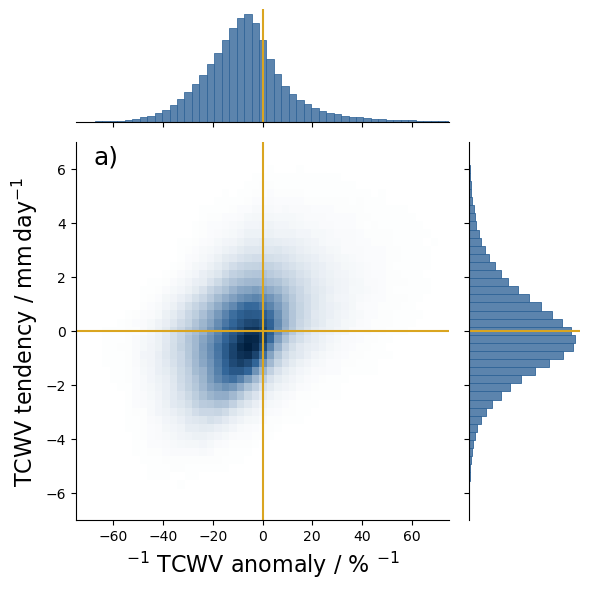

In [23]:
plot = sns.jointplot(data=ds, y='dtcwv_lead4to1', x='tcwv_anom_lead0', kind='hist', joint_kws={'cmap': cmap}, ratio = 3, ylim=(-7,7), xlim=(-75,75), binwidth=(3, 0.3), 
                     marginal_kws={'color':'#336699', 'edgecolor': '#336699', 'alpha':0.8})
plot.ax_joint.axvline(x=0, color = 'goldenrod', linewidth = 1.5)
plot.ax_joint.axhline(y=0, color = 'goldenrod', linewidth = 1.5)
plot.ax_marg_x.axvline(x=0.0, color='goldenrod', linewidth=1.5)
plot.ax_marg_y.axhline(y=0.0, color='goldenrod', linewidth=1.5)
plot.ax_joint.text(-68, 6.2, "a)", fontsize=fs)
plot.set_axis_labels('$^{-1}$ TCWV anomaly / % $^{-1}$', 'TCWV tendency / mm$\,$day$^{-1}$', fontsize=fs-2)
plot.figure.tight_layout()
plot.savefig(figure_folder + 'joint_hist_dtcwv_versus_tcwv_anomaly_before_hd.png', dpi=200)

In [24]:
ds['ai_cat'] = xr.where(
    ds.ai_percentile <= 25, 'arid',    
    xr.where(
        ds.ai_percentile <= 50, 'semi-arid',
        xr.where(
            ds.ai_percentile <= 75, 'semi-moist', 
            'moist'
        )
    )
)

/tmp/ipykernel_808105/1797179004.py:1: FutureWarning: Deleting a single level of a MultiIndex is deprecated. Previously, this deleted all levels of a MultiIndex. Please also drop the following variables: {'new_dim'} to avoid an error in the future.
  ds['ai_cat'] = xr.where(


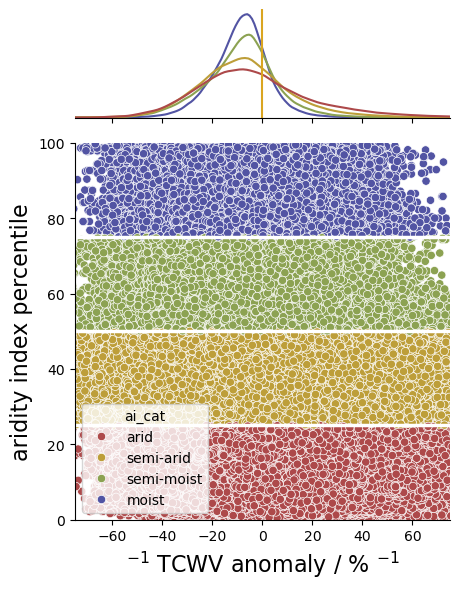

In [25]:
plot = sns.jointplot(data=ds, y='ai_percentile', x='tcwv_anom_lead0',  hue='ai_cat', 
                     palette=ai_palette, hue_order=['arid','semi-arid','semi-moist','moist'], 
                     ratio = 3, ylim=(0,100), xlim=(-75,75), 
                     marginal_kws={'fill':False})
sns.move_legend(
    plot.ax_joint,
    loc="lower left")
plot.ax_marg_x.axvline(x=0.0, color='goldenrod', linewidth=1.5)
plot.ax_marg_y.axhline(y=0.0, color='goldenrod', linewidth=1.5)
for val in [25,50,75]:  
    plot.ax_joint.axhline(y=val, color= 'white', linewidth = 2.5)
plot.ax_marg_y.remove()
plot.set_axis_labels('$^{-1}$ TCWV anomaly / % $^{-1}$', 'aridity index percentile', fontsize=fs-2)
plot.figure.tight_layout()
plot.savefig(figure_folder + 'joint_hist_ai_versus_tcwv_anomaly_regimes_as_hue.png', dpi=200)

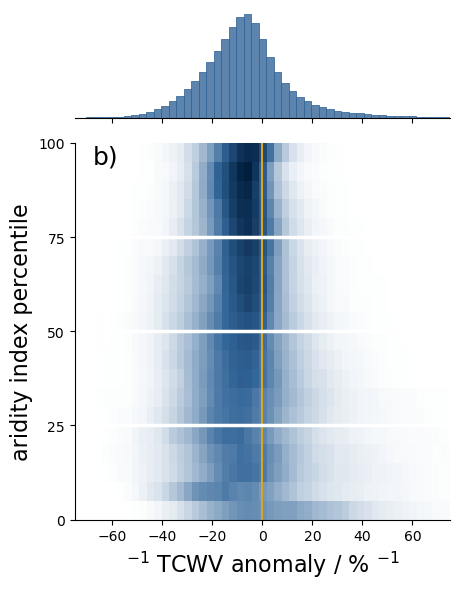

In [26]:
plot = sns.jointplot(data=ds, y='ai_percentile', x='tcwv_anom_lead0', kind='hist', joint_kws={'cmap': cmap}, ratio = 3, ylim=(0,100), xlim=(-75,75), binwidth=(3, 5),
                     marginal_kws={'color':'#336699', 'edgecolor': '#336699', 'alpha':0.8})
plot.ax_joint.axvline(x=0, color = 'goldenrod', linewidth = 1.5)
plot.ax_joint.set_yticks([0, 25, 50, 75, 100])
plot.ax_marg_y.remove()
for val in [25,50,75]:  
    plot.ax_joint.axhline(y=val, color= 'white', linewidth = 2.5)
plot.ax_joint.text(-68, 94.5, "b)", fontsize=fs)
plot.set_axis_labels('$^{-1}$ TCWV anomaly / % $^{-1}$', 'aridity index percentile', fontsize=fs-2)
plot.figure.tight_layout()
plot.savefig(figure_folder + 'joint_hist_ai_versus_tcwv_anomaly_ai_bin=5.png', dpi=200)

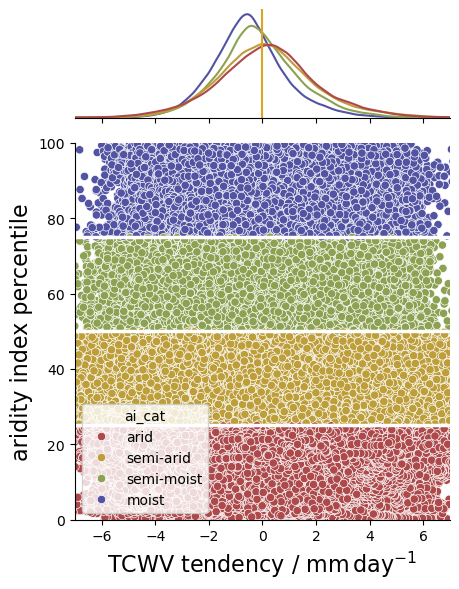

In [27]:
plot = sns.jointplot(data=ds, x='dtcwv_lead4to1', y='ai_percentile', hue='ai_cat', 
                     palette=ai_palette, hue_order=['arid','semi-arid','semi-moist','moist'], 
                     ratio = 3, xlim=(-7,7), ylim=(0,100), 
                     marginal_kws={'fill':False})
sns.move_legend(
    plot.ax_joint,
    loc="lower left")
plot.ax_marg_x.axvline(x=0.0, color='goldenrod', linewidth=1.5)
plot.ax_marg_y.axhline(y=0.0, color='goldenrod', linewidth=1.5)
for val in [25,50,75]:  
    plot.ax_joint.axhline(y=val, color= 'white', linewidth = 2.5)
plot.ax_marg_y.remove()
plot.set_axis_labels(r'TCWV tendency / mm$\,$day$^{-1}$', 'aridity index percentile', fontsize=fs-2)
plot.figure.tight_layout()
plot.savefig(figure_folder + 'joint_hist_ai_versus_dtcwv_before_hd_regimes_as_hue.png', dpi=200)

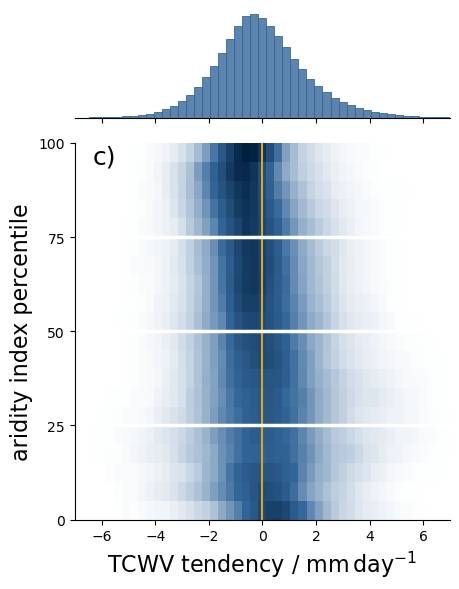

In [28]:
plot = sns.jointplot(data=ds, x='dtcwv_lead4to1', y='ai_percentile', kind='hist', joint_kws={'cmap': cmap}, ratio = 3, xlim=(-7,7), ylim=(0,100), binwidth=(0.3, 5),
                     marginal_kws={'color':'#336699', 'edgecolor': '#336699', 'alpha':0.8})
plot.ax_joint.axvline(x=0, color = 'goldenrod', linewidth = 1.5)
plot.ax_joint.set_yticks([0, 25, 50, 75, 100])
plot.ax_marg_y.remove()
for val in [25,50,75]:  
    plot.ax_joint.axhline(y=val, color= 'white', linewidth = 2.5)
plot.ax_joint.text(-6.32, 94.5, "c)", fontsize=fs)
plot.set_axis_labels(r'TCWV tendency / mm$\,$day$^{-1}$', 'aridity index percentile', fontsize=fs-2)
plot.figure.tight_layout()
plot.savefig(figure_folder + 'joint_hist_ai_versus_dtcwv_before_hd_ai_bin=5.png', dpi=200)

## Explaining the TCWV baseline difference between drying and moistening cases

In [16]:
# By how many days do drying and moistening events typically differ if they both occur within a window of 30 days?
dex = dex.assign(doy = dex.time.dt.dayofyear)
timing_drying = dex.where(land & drying).sel(lead_time = 0).doy.mean('year')
timing_moistening = dex.where(land & moistening).sel(lead_time = 0).doy.mean('year')
dex['timing_diff'] = timing_drying - timing_moistening
weights = np.cos(np.deg2rad(dex.latitude))
timing_diff_avg = dex.timing_diff.where((abs(dex.timing_diff) < 30)).weighted(weights).mean(['latitude', 'longitude']).values
timing_diff_avg_notweighted = dex.timing_diff.where((abs(dex.timing_diff) < 30)).mean(['latitude', 'longitude']).values
print('The average time difference between moistening and drying cases is: ', timing_diff_avg)
print('The average time difference between moistening and drying cases (unweighted) is: ', timing_diff_avg_notweighted)

The average time difference between moistening and drying cases is:  3.6972581089691716
The average time difference between moistening and drying cases (unweighted) is:  3.6981301397100914


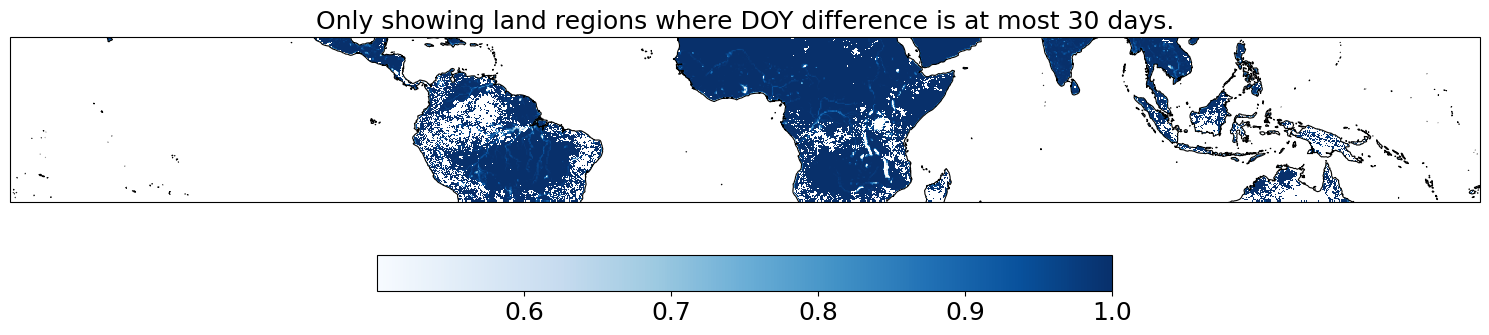

In [26]:
fig, ax = plt.subplots(figsize=(15, 4), subplot_kw={"projection": ccrs.PlateCarree()})
ax.coastlines(lw=0.8)
dex.lsm.where((abs(dex.timing_diff) < 30)).plot(ax=ax, cmap='Blues', cbar_kwargs={"location": "bottom", "shrink": 0.5})
# Access colorbar from figure
cbar = fig.axes[-1]  # Last axis is usually the colorbar
cbar.set_xlabel("", fontsize=fs)
cbar.tick_params(labelsize=fs)
ax.set_title("Only showing land regions where DOY difference is at most 30 days.", fontsize=fs)
plt.tight_layout()

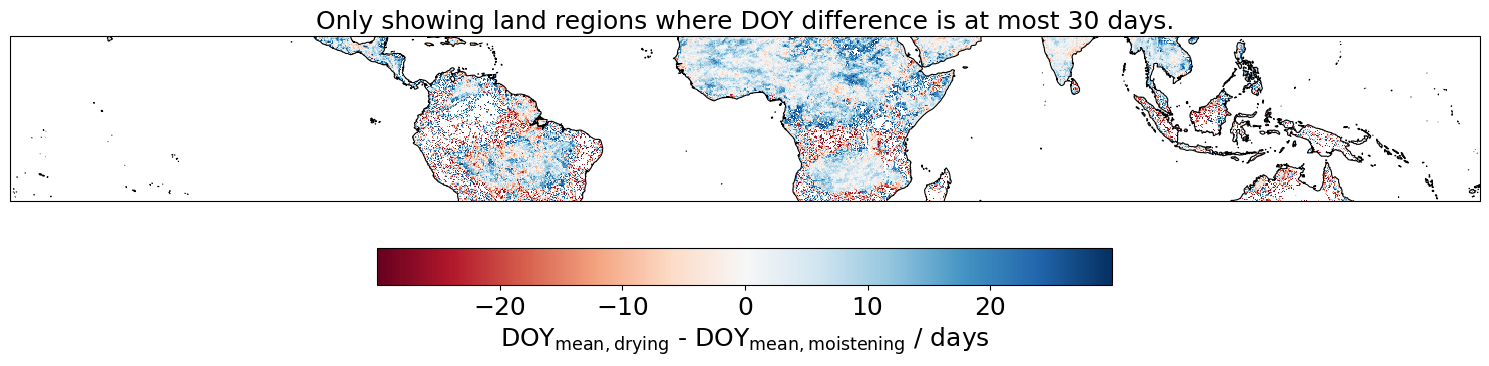

In [ ]:
# Potential supplementary figure
fig, ax = plt.subplots(figsize=(15, 4), subplot_kw={"projection": ccrs.PlateCarree()})
ax.coastlines(lw=0.8)
dex.timing_diff.where(abs(dex.timing_diff)<30).plot(ax=ax, cmap='RdBu', cbar_kwargs={"location": "bottom", "shrink": 0.5})
# Access colorbar from figure
cbar = fig.axes[-1]  # Last axis is usually the colorbar
cbar.set_xlabel(r"DOY$_\mathrm{mean,drying}$ - DOY$_\mathrm{mean,moistening}$ / days", fontsize=fs)
cbar.tick_params(labelsize=fs)
ax.set_title("Only showing land regions where DOY difference is at most 30 days.", fontsize=fs)
plt.tight_layout()

In [6]:
# Is there a systematic climatological difference between the days on which drying/moistening cases occur?
tcwv_clim = xr.open_dataset(f'/gws/ssde/j25b/global_ex/lms47/data/era5_derivatives/doy_climatologies/era5_doy_climatology_var=tcwv_region=tropics_timedim=doy_mode=simple_mean_from_smoothed_timeseries_ws=21.nc')
dex['tcwv_clim'] = tcwv_clim['tcwv_clim'].sel(dayofyear = dex.time.dt.dayofyear)

In [18]:
weights = np.cos(np.deg2rad(dex.latitude))
tcwv_clim_drying = dex['tcwv_clim'].sel(lead_time = 0).where(land & drying).weighted(weights).mean(['latitude', 'longitude', 'year'])
tcwv_clim_moistening = dex['tcwv_clim'].sel(lead_time = 0).where(land & moistening).weighted(weights).mean(['latitude', 'longitude', 'year'])

In [19]:
print('The average TCWV difference between drying and moistening events on the hottest day is: ', (tcwv_clim_drying - tcwv_clim_moistening).values)

The average TCWV difference between drying and moistening events on the hottest day is:  4.772217


# T & TCWV composite timeseries (Figure 2)

In [29]:
dmoist_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemimoist_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemiarid_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
darid_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')  
ocean_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_docean_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')

dmoist_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemimoist_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemiarid_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
darid_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
ocean_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_docean_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')

In [34]:
# T2m baseline difference between arid and moist regime in drying and moistening sample
t2m_aridity_diff_drying = darid_drying.t2m.sel(lead_time=slice(-16,-12)).mean().values - dmoist_drying.t2m.sel(lead_time=slice(-16,-12)).mean().values
t2m_aridity_diff_moistening = darid_moistening.t2m.sel(lead_time=slice(-16,-12)).mean().values - dmoist_moistening.t2m.sel(lead_time=slice(-16,-12)).mean().values
print(t2m_aridity_diff_drying, t2m_aridity_diff_moistening, " --> the baseline temperature differs by about 5K between arid and moist regimes.")

5.563812255859375 5.3385009765625  --> the baseline temperature differs by about 5K between arid and moist regimes.


In [35]:
# T2m hot day difference between arid and moist regime in drying and moistening sample
t2m_aridity_diff_drying = darid_drying.t2m.sel(lead_time=0).mean().values - dmoist_drying.t2m.sel(lead_time=0).mean().values
t2m_aridity_diff_moistening = darid_moistening.t2m.sel(lead_time=0).mean().values - dmoist_moistening.t2m.sel(lead_time=0).mean().values
print(t2m_aridity_diff_drying, t2m_aridity_diff_moistening, " --> the hot day temperature differs by about 6K between arid and moist regimes.")

6.5579833984375 6.430267333984375  --> the hot day temperature differs by about 6K between arid and moist regimes.


In [33]:
# TCWV baseline difference between arid and moist regime in drying and moistening sample
aridity_diff_drying = (dmoist_drying.tcwv.sel(lead_time=slice(-16,-12)).mean().values - darid_drying.tcwv.sel(lead_time=slice(-16,-12)).mean().values) / dmoist_drying.tcwv.sel(lead_time=slice(-16,-12)).mean().values
aridity_diff_moistening = (dmoist_moistening.tcwv.sel(lead_time=slice(-16,-12)).mean().values - darid_moistening.tcwv.sel(lead_time=slice(-16,-12)).mean().values) / dmoist_moistening.tcwv.sel(lead_time=slice(-16,-12)).mean().values
print(aridity_diff_drying, aridity_diff_moistening, " --> the arid regime is generally about 40 percent drier than the moist regime.")

0.4032231026369181 0.40714486640676567  --> the arid regime is generally about 40 percent drier than the moist regime.


In [36]:
# baseline difference between drying and moistening sample for moist, semi-moist, semi-arid, and arid regime, respectively, in relative terms
time_slice = slice(-16,-12)
diff_moist = (dmoist_drying.tcwv.sel(lead_time=time_slice).mean().values - dmoist_moistening.tcwv.sel(lead_time=time_slice).mean().values) / dmoist_drying.tcwv.sel(lead_time=time_slice).mean().values
diff_semimoist = (dsemimoist_drying.tcwv.sel(lead_time=time_slice).mean().values - dsemimoist_moistening.tcwv.sel(lead_time=time_slice).mean().values) / dsemimoist_drying.tcwv.sel(lead_time=time_slice).mean().values
diff_semiarid = (dsemiarid_drying.tcwv.sel(lead_time=time_slice).mean().values - dsemiarid_moistening.tcwv.sel(lead_time=time_slice).mean().values) / dsemiarid_drying.tcwv.sel(lead_time=time_slice).mean().values
diff_arid = (darid_drying.tcwv.sel(lead_time=time_slice).mean().values - darid_moistening.tcwv.sel(lead_time=time_slice).mean().values) / darid_drying.tcwv.sel(lead_time=time_slice).mean().values
print(diff_moist, diff_semimoist, diff_semiarid, diff_arid, "\n--> the moistening cases happen in a 10-12 percent drier environment than the drying cases. \nThis difference stems mostly from moistening events occurring at a climatologically drier time of the year.")


0.10714392116483525 0.10889538525788264 0.0943041237968282 0.11301139129837419 
--> the moistening cases happen in a 10-12 percent drier environment than the drying cases. 
This difference stems mostly from moistening events occurring at a climatologically drier time of the year.


In [38]:
# baseline difference between drying and moistening sample for moist, semi-moist, semi-arid, and arid regime, respectively, in absolute terms
time_slice = slice(-16,-12)
abs_diff_moist = (dmoist_drying.tcwv.sel(lead_time=time_slice).mean().values - dmoist_moistening.tcwv.sel(lead_time=time_slice).mean().values)
abs_diff_semimoist = (dsemimoist_drying.tcwv.sel(lead_time=time_slice).mean().values - dsemimoist_moistening.tcwv.sel(lead_time=time_slice).mean().values)
abs_diff_semiarid = (dsemiarid_drying.tcwv.sel(lead_time=time_slice).mean().values - dsemiarid_moistening.tcwv.sel(lead_time=time_slice).mean().values)
abs_diff_arid = (darid_drying.tcwv.sel(lead_time=time_slice).mean().values - darid_moistening.tcwv.sel(lead_time=time_slice).mean().values)
print(abs_diff_moist, abs_diff_semimoist, abs_diff_semiarid, abs_diff_arid, "\n--> the moistening cases happen in a 3-5 mm drier environment than the drying cases. \nThis difference stems mostly from moistening events occurring at a climatologically drier time of the year.")


4.815330505371094 3.9866867065429688 2.928314208984375 3.031047821044922 
--> the moistening cases happen in a 3-5 mm drier environment than the drying cases. 
This difference stems mostly from moistening events occurring at a climatologically drier time of the year.


In [11]:
# hot day difference between drying and moistening sample for moist, semi-moist, semi-arid, and arid regime, respectively
diff_moist = (dmoist_drying.tcwv.sel(lead_time=0).values - dmoist_moistening.tcwv.sel(lead_time=0).values) / dmoist_drying.tcwv.sel(lead_time=0).values
diff_semimoist = (dsemimoist_drying.tcwv.sel(lead_time=0).values - dsemimoist_moistening.tcwv.sel(lead_time=0).values) / dsemimoist_drying.tcwv.sel(lead_time=0).values
diff_semiarid = (dsemiarid_drying.tcwv.sel(lead_time=0).values - dsemiarid_moistening.tcwv.sel(lead_time=0).values) / dsemiarid_drying.tcwv.sel(lead_time=0).values
diff_arid = (darid_drying.tcwv.sel(lead_time=0).values - darid_moistening.tcwv.sel(lead_time=0).values) / darid_drying.tcwv.sel(lead_time=0).values
print(diff_moist, diff_semimoist, diff_semiarid, diff_arid, '\n--> by the time of the hottest day itself, humidity differences between moistening and drying have been significantly reduced. \nThe difference in initial conditions would have gone unnoticed when compiling hot day statistics alone without the temporal evolution towards it.')

0.0054924716 -0.007523941 -0.065333515 -0.06224858 
--> by the time of the hottest day itself, humidity differences between moistening and drying have been significantly reduced. 
The difference in initial conditions would have gone unnoticed when compiling hot day statistics alone without the temporal evolution towards it.


In [40]:
dmoist_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemimoist_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemiarid_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
darid_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')  

dmoist_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemimoist_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemiarid_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
darid_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')

In [13]:
dmoist_drying_clim

<xarray.Dataset> Size: 2kB
Dimensions:              (lead_time: 31)
Coordinates:
  * lead_time            (lead_time) int64 248B -20 -19 -18 -17 -16 ... 7 8 9 10
Data variables:
    t2m_diff_clim_abs    (lead_time) float32 124B ...
    tcwv_diff_clim_abs   (lead_time) float32 124B ...
    q2m_diff_clim_abs    (lead_time) float32 124B ...
    mer_diff_clim_abs    (lead_time) float32 124B ...
    mvimd_diff_clim_abs  (lead_time) float32 124B ...
    mtpr_diff_clim_abs   (lead_time) float32 124B ...
    t2m_diff_clim_rel    (lead_time) float32 124B ...
    tcwv_diff_clim_rel   (lead_time) float32 124B ...
    q2m_diff_clim_rel    (lead_time) float32 124B ...
    mer_diff_clim_rel    (lead_time) float32 124B ...
    mvimd_diff_clim_rel  (lead_time) float32 124B ...
    mtpr_diff_clim_rel   (lead_time) float32 124B ...
Attributes:
    acknowledgment:    Contains Copernicus Climate Change Service information...
    contact:           lms47@st-andrews.ac.uk
    creator:           Luca Schmidt
    description:       Hot day full column moisture budget components
    source:            The dataset is based on ERA5 reanalysis data and conta...
    valid_time_start:  1980-01-01
    valid_time_stop:   2023-12-31

In [41]:
# baseline difference between drying and moistening sample for moist, semi-moist, semi-arid, and arid regime, respectively, in absolute terms
time_slice = slice(-16,-12)
abs_diff_clim_moist = (dmoist_drying_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values - dmoist_moistening_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values)
abs_diff_clim_semimoist = (dsemimoist_drying_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values - dsemimoist_moistening_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values)
abs_diff_clim_semiarid = (dsemiarid_drying_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values - dsemiarid_moistening_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values)
abs_diff_clim_arid = (darid_drying_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values - darid_moistening_clim.tcwv_diff_clim_abs.sel(lead_time=time_slice).mean().values)
print(abs_diff_clim_moist, abs_diff_clim_semimoist, abs_diff_clim_semiarid, abs_diff_clim_arid, "\n--> the moistening cases happen in a 10-12 percent drier environment than the drying cases. \nThis difference stems mostly from moistening events occurring at a climatologically drier time of the year.")


0.8659810423851013 0.6800931096076965 0.6812232732772827 0.1509169340133667 
--> the moistening cases happen in a 10-12 percent drier environment than the drying cases. 
This difference stems mostly from moistening events occurring at a climatologically drier time of the year.


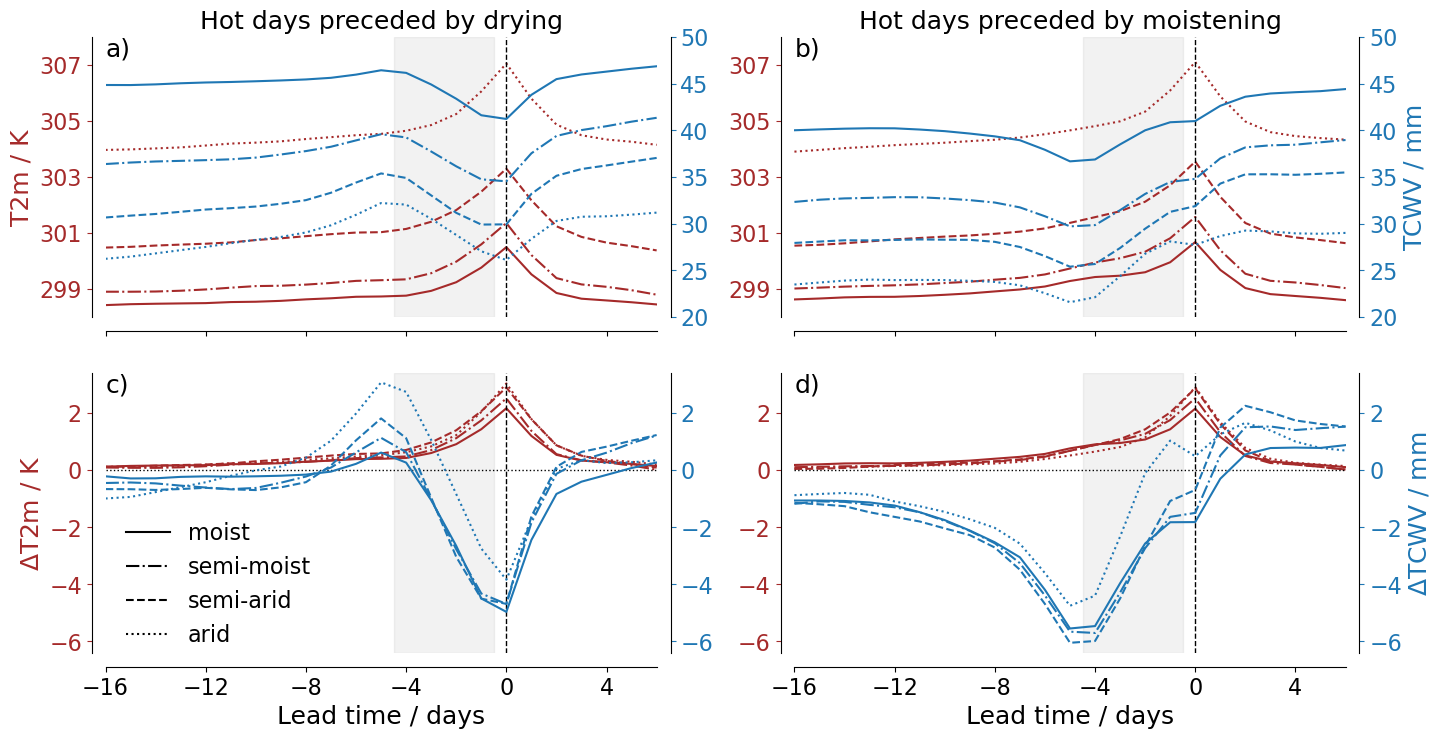

In [ ]:
# same y-axis limits for drying and moistening
time_slice = slice(-16,6)
legend_handles = [Line2D([0], [0], color='k', linestyle=ls, label=label) for ls, label in zip(aridity_linestyle, aridity_levels_names)]

fig, ax = plt.subplots(2,2, figsize=(16,8), sharex=True, gridspec_kw={'wspace': 0.25})
lead_time = dmoist_drying.lead_time.sel(lead_time = time_slice)

#define twin axes for TCWV variables
ax_extra00 = ax[0,0].twinx()
ax_extra01 = ax[0,1].twinx()
ax_extra10 = ax[1,0].twinx()
ax_extra11 = ax[1,1].twinx()

# plot t2m & TCWV for drying cases
for i, (data, label, style) in enumerate(zip(
    [dmoist_drying.sel(lead_time = time_slice), dsemimoist_drying.sel(lead_time = time_slice), dsemiarid_drying.sel(lead_time = time_slice), darid_drying.sel(lead_time = time_slice)],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,0].plot(lead_time, data.t2m, linestyle=style, color=var_colors['T'])
    ax_extra00.plot(lead_time, data.tcwv, linestyle=style, color=var_colors['TCWV'])

# plot Δt2m & ΔTCWV for drying cases
for i, (data, label, style) in enumerate(zip(
    [dmoist_drying_clim.sel(lead_time = time_slice), dsemimoist_drying_clim.sel(lead_time = time_slice), dsemiarid_drying_clim.sel(lead_time = time_slice), darid_drying_clim.sel(lead_time = time_slice)],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[1,0].plot(lead_time, data.t2m_diff_clim_abs, linestyle=style, color=var_colors['T'], label=label)
    ax_extra10.plot(lead_time, data.tcwv_diff_clim_abs, linestyle=style, color=var_colors['TCWV'])

# plot t2m & TCWV for moistening cases
for i, (data, label, style) in enumerate(zip(
    [dmoist_moistening.sel(lead_time = time_slice), dsemimoist_moistening.sel(lead_time = time_slice), dsemiarid_moistening.sel(lead_time = time_slice), darid_moistening.sel(lead_time = time_slice)],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,1].plot(lead_time, data.t2m, linestyle=style, color=var_colors['T'])
    ax_extra01.plot(lead_time, data.tcwv, linestyle=style, color=var_colors['TCWV'], label=label)

# plot Δt2m & ΔTCWV for moistening cases
for i, (data, label, style) in enumerate(zip(
    [dmoist_moistening_clim.sel(lead_time = time_slice), dsemimoist_moistening_clim.sel(lead_time = time_slice), dsemiarid_moistening_clim.sel(lead_time = time_slice), darid_moistening_clim.sel(lead_time = time_slice)],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[1,1].plot(lead_time, data.t2m_diff_clim_abs, linestyle=style, color=var_colors['T'])
    ax_extra11.plot(lead_time, data.tcwv_diff_clim_abs, linestyle=style, color=var_colors['TCWV'])


# set y-axis limits
for a in [ax[0,0], ax[0,1]]:
    a.set_ylim(298,308)
    a.set_xlim(-16, 6)
    a.set_yticks([299, 301, 303, 305, 307])
for a in [ax_extra00, ax_extra01]:
    a.set_ylim(20,50)
for a in [ax[1,0], ax[1,1], ax_extra10, ax_extra11]:
    a.set_ylim(-6.4,3.4)

# add zero line for reference
for a in [ax[1,0], ax[1,1]]:
    a.axhline(0, color='k', linestyle=':', linewidth=1)
for a in ax.flat:
    a.axvline(0, color='k', linestyle='dashed', linewidth=1)
    a.axvspan(-4.5, -0.5, color="gray", alpha=0.1, zorder=0)
    #a.axvline(-4, color='tab:red', linestyle = 'dashed', linewidth=1)

# set labels and colorcoding
ax[0,0].set_ylabel('T2m / K', color=var_colors['T'], fontsize=fs)
ax_extra01.set_ylabel('TCWV / mm', color=var_colors['TCWV'], fontsize=fs)
ax[1,0].set_ylabel(r'$\Delta$T2m / K', color=var_colors['T'], fontsize=fs)
ax_extra11.set_ylabel(r'$\Delta$TCWV / mm', color=var_colors['TCWV'], fontsize=fs)
for a in [ax[1,0], ax[1,1]]:
    a.set_xlabel('Lead time / days', fontsize=fs)
    a.set_xticks([-16, -12, -8, -4, 0, 4])
ax[0,0].set_title('Hot days preceded by drying', fontsize=fs)
ax[0,1].set_title('Hot days preceded by moistening', fontsize=fs)
for a in [ax[0,0], ax[1,0], ax[0,1], ax[1,1]]:    
    a.tick_params(axis='y', colors=var_colors['T'], labelsize=fs-2)
for a in [ax_extra00, ax_extra01, ax_extra10, ax_extra11]:
    a.tick_params(axis='y', colors=var_colors['TCWV'], which='major', labelsize=fs-2)

# add legend and subplot label
ax[1,0].legend(legend_handles, aridity_levels_names, frameon=False,fontsize = fs-2, loc='lower left', bbox_to_anchor=(0.0, -0.05), bbox_transform=ax[1,0].transAxes)
for i, (a, label) in enumerate(zip([ax[0,0], ax[0,1], ax[1,0], ax[1,1]], ['a)', 'b)', 'c)', 'd)'])):
    a.text(0, 1, label, transform=a.transAxes, ha='left', va='top', fontsize=fs)
    
# adjust spines
for a in ax.flat:
    sns.despine(ax=a, offset = 10)
    a.tick_params(axis='both', which='major', labelsize=fs-2)
for a in [ax_extra00, ax_extra01, ax_extra10, ax_extra11]:
    sns.despine(ax=a, top=True, left=True, bottom=True, right=False, offset=10)
    a.spines['right'].set_visible(True)
    a.yaxis.set_ticks_position('right')
#plt.savefig(figure_folder + 'full_col_T2m_and_TCWV_composites.png', bbox_inches='tight', dpi=300)

# Spatial & temporal variability (Figure 3)

In [11]:
# hatching threshold (percentage of hot days falling into a common 31-day window in the seasonal cycle)
hatch_thres = 60

# add moisture change variable
dex = dex.assign(dtcwv_m4to1 = dex['d_tcwv_dt'].sel(lead_time=lead_time_window_dq).mean('lead_time'))

# add month and dayofyear variable
dex = dex.assign(month = dex.time.dt.month)

drying = (dex['dtcwv_m4to1'] < -epsilon)
moistening = (dex['dtcwv_m4to1'] > epsilon)
land = dex.lsm > land_thres

In [17]:
# # add month with highest occurrence of hot day extremes in drying and moistening category, respectively
# max_month_drying = mode(dex.where(drying).sel(lead_time=0).month.values, axis=0, keepdims=True, nan_policy='omit')
# dex = dex.assign(max_month_drying = (('latitude', 'longitude'), max_month_drying.mode[0]))

# max_month_moistening = mode(dex.where(moistening).sel(lead_time=0).month.values, axis=0, keepdims=True, nan_policy='omit')
# dex = dex.assign(max_month_moistening = (('latitude', 'longitude'), max_month_moistening.mode[0]))

# # prepare boolean mask for hatching
# nb_drying = xr.where(drying, 1, np.nan).sum('year')
# month_count_drying = ((dex.sel(lead_time=0).time.where(drying).dt.month == dex.max_month_drying).sum(dim='year') / nb_drying) * 100
# drying_larger_50 = xr.where(month_count_drying > 50, 1.0, np.nan)

# nb_moistening = moistening.sum('year')
# month_count_moistening = ((dex.sel(lead_time=0).time.where(moistening).dt.month == dex.max_month_moistening).sum(dim='year') / nb_moistening) * 100
# moistening_larger_50 = xr.where(month_count_moistening > 50, 1.0, np.nan)

In [ ]:
half_width = 15          # 31-day window
ndays = 365              # leap days are folded onto a 365-day calendar
 
# month of each day of a non-leap year (index 0 = 1 Jan) --> array of length 365 with values in 1..12
month_of_doy = pd.date_range('2001-01-01', periods=ndays, freq='D').month.values
 
# day of year of each hot day (lead_time = 0), mapped to a 365-day calendar
t_hd = dex.sel(lead_time=0).time
doy_hd = t_hd.dt.dayofyear
doy_hd = xr.where(t_hd.dt.is_leap_year & (doy_hd > 59), doy_hd - 1, doy_hd)   # 29 Feb --> 28 Feb, later days shift back by one
doy_hd = doy_hd.transpose('year', 'latitude', 'longitude')
 
def peak_window(doy_hd, valid_hd, half_width=half_width, ndays=ndays):
    """For each grid cell, find the 31-day window (circular in the seasonal
    cycle) containing the most hot days.
 
    doy   : (year, lat, lon) day of year in 1..ndays
    valid_hd  : (year, lat, lon) bool, which hot days to count for given event type (drying or moistening)
    Returns center day of the peak window (1..ndays), number of hot days in
    that window, and total number of counted hot days.
    """
    doy_hd = np.asarray(doy_hd)
    valid_hd = np.asarray(valid_hd)
    valid_hd = valid_hd & np.isfinite(doy_hd)
    doy_hd_idx = np.where(valid_hd, doy_hd, 1).astype(int) - 1
    nyear, nlat, nlon = doy_hd.shape
 
    # histogram of hot days per calendar day and grid cell
    counts = np.zeros((ndays, nlat, nlon), dtype=np.int16) # counts(d, j, i) holds the number of years in which the hot day at grid cell (j, i) fell on calendar day d+1
    jj, ii = np.meshgrid(np.arange(nlat), np.arange(nlon), indexing='ij') # hold the latitude and longitude indices of every cell
    for y in range(nyear): # for each year, every valid cell adds 1 at its own position
        v = valid_hd[y] # 2D boolean map for year y (lat, lon)
        counts[doy_hd_idx[y][v], jj[v], ii[v]] += 1
 
    # circular running sum over 2*half_width+1 days (wraps Dec -> Jan)
    w = 2 * half_width + 1
    padded = np.concatenate([counts[-half_width:], counts, counts[:half_width]], axis=0)
    cs = np.cumsum(padded, axis=0, dtype=np.int32)
    cs = np.concatenate([np.zeros((1, nlat, nlon), np.int32), cs], axis=0)
    window_counts = cs[w:] - cs[:-w]          # (ndays, lat, lon), index k = window centred on day k+1
 
    center = window_counts.argmax(axis=0) + 1
    max_count = window_counts.max(axis=0)
    total = valid_hd.sum(axis=0)
    return center, max_count, total
 
def window_fields(event_type_mask):
    center, max_count, total = peak_window(doy_hd.values, event_type_mask.transpose('year', 'latitude', 'longitude').values)
    coords = {'latitude': dex.latitude, 'longitude': dex.longitude}
    dims = ('latitude', 'longitude')
    peak_month = xr.DataArray(month_of_doy[center - 1].astype(float), coords=coords, dims=dims)
    peak_month = peak_month.where(total > 0)
    pct = xr.DataArray(np.where(total > 0, 100 * max_count / np.maximum(total, 1), np.nan),
                       coords=coords, dims=dims)
    return peak_month, pct
 
# month of the centre day of the peak 31-day window
max_month_drying, window_pct_drying = window_fields(drying)
max_month_moistening, window_pct_moistening = window_fields(moistening)
dex = dex.assign(max_month_drying = max_month_drying,
                 max_month_moistening = max_month_moistening)
 
# boolean mask for hatching: > 50 % of hot days fall into the peak 31-day window
drying_larger_50 = xr.where(window_pct_drying > hatch_thres, 1.0, np.nan)
moistening_larger_50 = xr.where(window_pct_moistening > hatch_thres, 1.0, np.nan)
 
 

In [13]:
# # add all-day climatological w500 for zero contour line
# dex = dex.assign(w500_clim = xr.open_dataset(derivatives_folder + 'doy_climatologies/era5_doy_climatology_var=w500_region=tropics_timedim=doy_mode=simple_mean_from_smoothed_timeseries_ws=21.nc')['w500_clim'].mean('dayofyear'))

# # add climatological w500 around hot days for zero contour line
# dex = dex.assign(w500_clim_hd = xr.open_dataset(derivatives_folder + 'doy_climatologies/era5_doy_climatology_var=w500_region=tropics_timedim=doy_mode=simple_mean_from_smoothed_timeseries_ws=21.nc')['w500_clim'].sel(dayofyear = dex.time.dt.dayofyear).mean(['year', 'lead_time']))

# add mean w500 values around hot days for zero contour line
dex = dex.assign(w500_mean_hd = xr.open_dataset(derivatives_folder + 'era5_hot_day_met_vars_extreme_var=t2m_region=tropics.zarr')['w500'].mean(['year', 'lead_time']))

In [14]:
def discrete_pale_to_deep_colormap(base_color, n_bins=10):
    cmap_continuous = mcolors.LinearSegmentedColormap.from_list(
        "pale_to_deep", ["#ffffff", base_color]
    )
    colors = cmap_continuous(np.linspace(0.1, 1.0, n_bins))
    return mcolors.ListedColormap(colors)
N = 6
cmap_p2d = discrete_pale_to_deep_colormap("#5504A1", N)
# Bin edges from 0 to 100
levels = np.linspace(0, 100, N)
norm = mcolors.BoundaryNorm(levels, ncolors=cmap_p2d.N, clip=True)

In [15]:
# Define colors
deep_orange = "#f86401ff"
pale_orange = "#f8640188"
white = "#ffffff"
pale_blue = "#056cba93"
deep_blue = "#056cbaff"

# Build 5 orange bins and 5 blue bins
orange_colors = mcolors.LinearSegmentedColormap.from_list(
    "orange_to_pale", [pale_orange, deep_orange]
)(np.linspace(0, 1, 2))
blue_colors = mcolors.LinearSegmentedColormap.from_list(
    "pale_to_blue", [deep_blue, pale_blue]
)(np.linspace(0, 1, 2))

colors = np.vstack([blue_colors, [mcolors.to_rgba(white)], orange_colors])
cmap_bod = mcolors.ListedColormap(colors, name="blue_orange_diverging")

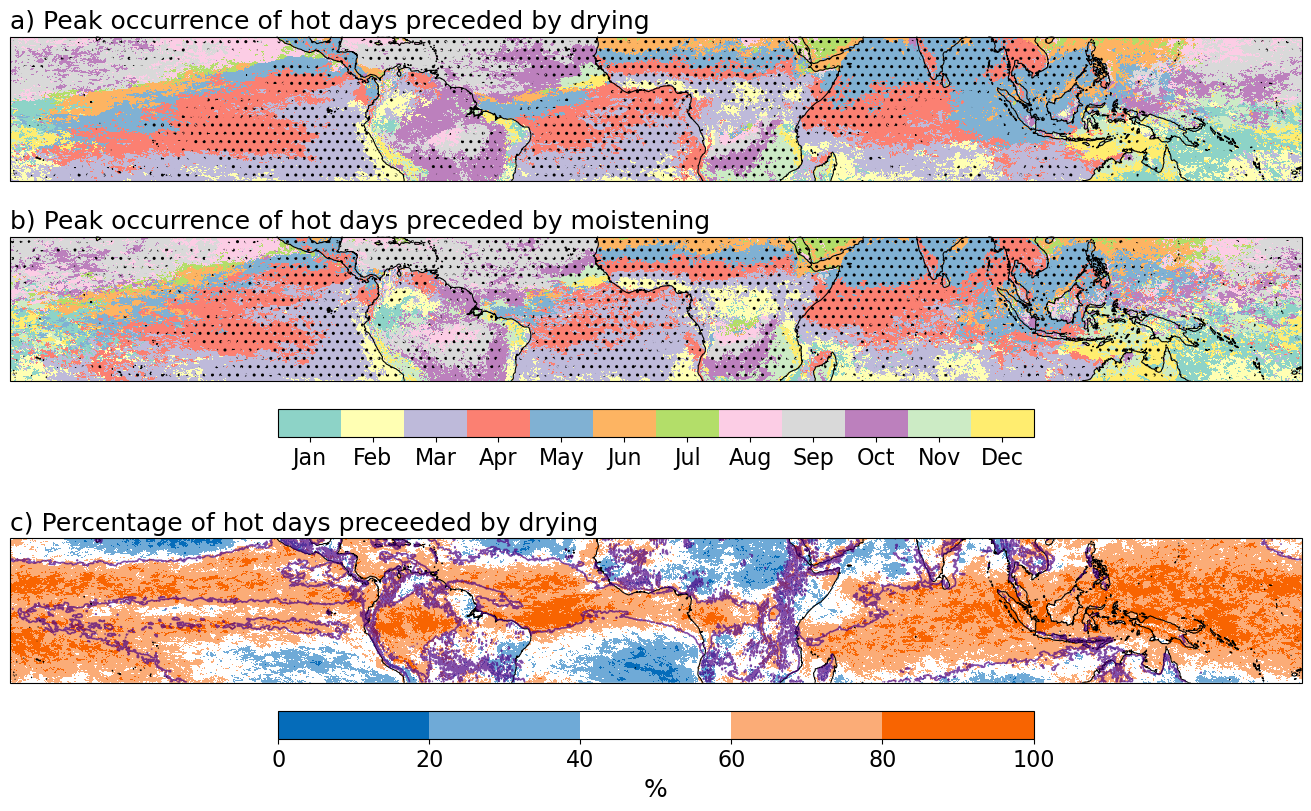

In [17]:
fig = plt.figure(figsize=(13, 8), constrained_layout=True)

gs = fig.add_gridspec(
    6, 5,
    height_ratios=[1, 1, 0.15, 0.18, 1, 0.15],
    hspace=0,
    wspace=0,
)
ax0 = fig.add_subplot(gs[0, :], projection=ccrs.PlateCarree())
ax1 = fig.add_subplot(gs[1, :], projection=ccrs.PlateCarree())
cax12 = fig.add_subplot(gs[2, 1:4])
ax2 = fig.add_subplot(gs[4, :], projection=ccrs.PlateCarree())
cax3 = fig.add_subplot(gs[5, 1:4])

p0 = dex.max_month_drying.plot(ax=ax0, cmap="Set3", vmin=0.5, vmax=12.5, add_colorbar=False)
h0 = drying_larger_50.plot.contourf(ax=ax0, levels=[0.5, 1.5], colors="none", hatches=[".."], add_colorbar=False)
p1 = dex.max_month_moistening.plot(ax=ax1, cmap="Set3", vmin=0.5, vmax=12.5, add_colorbar=False)
h1 = moistening_larger_50.plot.contourf(ax=ax1, levels=[0.5, 1.5], colors="none", hatches=[".."], add_colorbar=False)

p2 = (xr.where(drying, 1, 0).sum("year") * 100 / 44).plot(ax=ax2, cmap=cmap_bod, norm=norm, levels=levels, add_colorbar=False)
ax2.contour(
    dex["w500_mean_hd"].longitude.values,
    dex["w500_mean_hd"].latitude.values,
    dex["w500_mean_hd"].values,
    levels=[0],
    colors='indigo',
    linewidths=1.2,
    alpha=0.7
)

for a in [ax0, ax1, ax2]:
    a.coastlines(lw=0.8)
    a.set_title("")

ticks12 = np.arange(1, 13)
labels12 = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
cbar12 = fig.colorbar(p1, cax=cax12, orientation="horizontal")
cbar12.set_ticks(ticks12)
cbar12.set_ticklabels(labels12, fontsize=fs-2)

ticks3 = [0, 20, 40, 60, 80, 100]
cbar3 = fig.colorbar(p2, cax=cax3, orientation="horizontal")
cbar3.set_ticks(ticks3)
cbar3.set_ticklabels([str(tick) for tick in ticks3], fontsize=fs-2)
cbar3.set_label("%", fontsize=fs)

ax0.set_title('a) Peak occurrence of hot days preceded by drying', fontsize = fs, loc='left')
ax1.set_title('b) Peak occurrence of hot days preceded by moistening', fontsize = fs, loc='left')
ax2.set_title('c) Percentage of hot days preceeded by drying', fontsize = fs, loc='left')

plt.savefig(figure_folder + 'spatiotemporal_variability_drying_moistening_contour=w500climhd_stipplingcrit=60pct.png', bbox_inches='tight', dpi=300)

# Moisture budget composite timeseries (Figures 4, 5 and 7)

In [26]:
dmoist_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemimoist_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemiarid_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
darid_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')  
ocean_drying = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_docean_drying_dqcrit=' + dq_crit + '_epsilon=0.0.nc')

dmoist_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemimoist_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dsemiarid_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
darid_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
ocean_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_docean_moistening_dqcrit=' + dq_crit + '_epsilon=0.0.nc')

<>:53: SyntaxWarning: invalid escape sequence '\,'
<>:54: SyntaxWarning: invalid escape sequence '\,'
<>:55: SyntaxWarning: invalid escape sequence '\,'
<>:53: SyntaxWarning: invalid escape sequence '\,'
<>:54: SyntaxWarning: invalid escape sequence '\,'
<>:55: SyntaxWarning: invalid escape sequence '\,'
/tmp/ipykernel_475994/3544398546.py:53: SyntaxWarning: invalid escape sequence '\,'
  ax[1,0].set_ylabel('CONV / mm$\,$day$^{-1}$', fontsize=fs)
/tmp/ipykernel_475994/3544398546.py:54: SyntaxWarning: invalid escape sequence '\,'
  ax[2,0].set_ylabel('P / mm$\,$day$^{-1}$', fontsize=fs)
/tmp/ipykernel_475994/3544398546.py:55: SyntaxWarning: invalid escape sequence '\,'
  ax[3,0].set_ylabel('ET / mm$\,$day$^{-1}$', fontsize=fs)


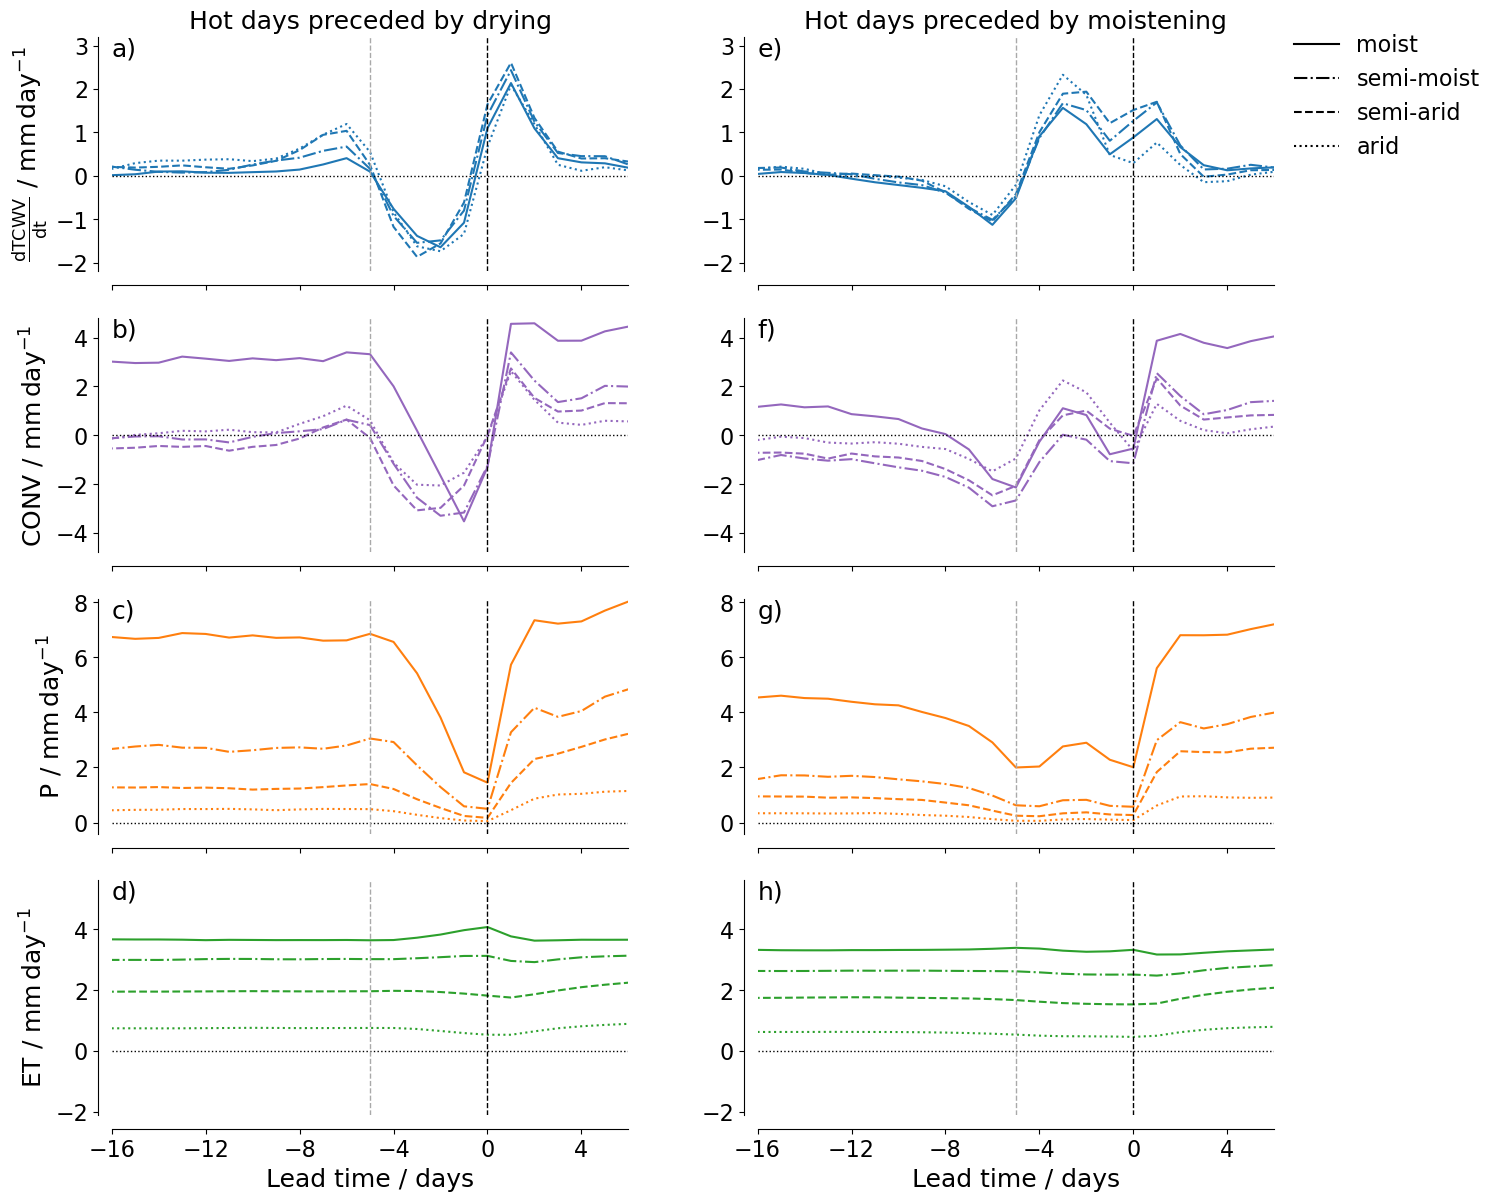

In [ ]:
# same y-axis limits for drying and moistening
legend_handles = [Line2D([0], [0], color='k', linestyle=ls, label=label) for ls, label in zip(aridity_linestyle, aridity_levels_names)]

fig, ax = plt.subplots(4,2, figsize=(15,14), sharex=True, gridspec_kw={'wspace': 0.25})
lead_time = dmoist_drying.lead_time

# plot moisture budget components for drying data subset
for i, (data, label, style) in enumerate(zip(
    [dmoist_drying, dsemimoist_drying, dsemiarid_drying, darid_drying],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,0].plot(lead_time, data.d_tcwv_dt, linestyle=style, color=var_colors['TCWV'])
    ax[1,0].plot(lead_time, -data.mvimd * secperday, linestyle=style, color=var_colors['CONV'])
    ax[2,0].plot(lead_time, data.mtpr * secperday, linestyle=style, color=var_colors['P'])
    ax[3,0].plot(lead_time, -data.mer * secperday, linestyle=style, color=var_colors['ET'])

# plot moisture budget components for moistening data subset
for i, (data, label, style) in enumerate(zip(
    [dmoist_moistening, dsemimoist_moistening, dsemiarid_moistening, darid_moistening],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,1].plot(lead_time, data.d_tcwv_dt, linestyle=style, color=var_colors['TCWV'])
    ax[1,1].plot(lead_time, -data.mvimd * secperday, linestyle=style, color=var_colors['CONV'])
    ax[2,1].plot(lead_time, data.mtpr * secperday, linestyle=style, color=var_colors['P'])
    ax[3,1].plot(lead_time, -data.mer * secperday, linestyle=style, color=var_colors['ET'])

# set y-axis limits
for a in [ax[0,0], ax[0,1]]:
    a.set_ylim(-2.2,3.2)
    a.set_yticks([-2.0,-1.0, 0, 1.0, 2.0, 3.0])
for a in [ax[1,0], ax[1,1]]:
    a.set_ylim(-4.8,4.8)
for a in [ax[2,0], ax[2,1]]:
    a.set_ylim(-0.4,8.1)
for a in [ax[3,0], ax[3,1]]:#, ax_pmc_drying, ax_pmc_moistening]:
    a.set_ylim(-2.1,5.6)
    a.set_xticks([-16, -12, -8, -4, 0, 4])

# add zero line for reference
for a in ax.flat:
    a.axhline(0, color='k', linestyle=':', linewidth=1)
    a.axvline(0, color='k', linestyle='dashed', linewidth=1)
    a.axvline(-5, color='darkgray', linestyle = 'dashed', linewidth=1)
    a.set_xlim(plot_start, plot_end)

# set labels, legends and aesthetics
ax[0,0].set_title('Hot days preceded by drying', fontsize=fs)
ax[0,1].set_title('Hot days preceded by moistening', fontsize=fs)
ax[0,0].set_ylabel(r'$\frac{\text{dTCWV}}{\text{dt}}$ / mm$\,$day$^{-1}$', fontsize=fs)
ax[0,1].legend(legend_handles, aridity_levels_names, frameon=False,fontsize = fs-2, loc='upper left', bbox_to_anchor=(1, 1.1), bbox_transform=ax[0,1].transAxes)
ax[1,0].set_ylabel('CONV / mm$\,$day$^{-1}$', fontsize=fs)
ax[2,0].set_ylabel('P / mm$\,$day$^{-1}$', fontsize=fs)
ax[3,0].set_ylabel('ET / mm$\,$day$^{-1}$', fontsize=fs)
ax[3,0].set_xlabel('Lead time / days', fontsize=fs)
ax[3,1].set_xlabel('Lead time / days', fontsize=fs)

# add subplot labels
for i, (a, label) in enumerate(zip([ax[0,0], ax[1,0], ax[2,0], ax[3,0], ax[0,1], ax[1,1], ax[2,1], ax[3,1]], ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)'])):
    a.text(0, 1, label, transform=a.transAxes, ha='left', va='top', fontsize=fs)
    
for a in ax.flat:
    sns.despine(ax=a, offset = 10)
    a.tick_params(axis='both', which='major', labelsize=fs-2)
#plt.savefig(figure_folder + 'full_col_moisture_budget_decomposition.png', bbox_inches='tight', dpi=300)

## Comparison with level at lead time -16 days

<>:83: SyntaxWarning: invalid escape sequence '\d'
<>:84: SyntaxWarning: invalid escape sequence '\d'
<>:85: SyntaxWarning: invalid escape sequence '\d'
<>:86: SyntaxWarning: invalid escape sequence '\d'
<>:83: SyntaxWarning: invalid escape sequence '\d'
<>:84: SyntaxWarning: invalid escape sequence '\d'
<>:85: SyntaxWarning: invalid escape sequence '\d'
<>:86: SyntaxWarning: invalid escape sequence '\d'
/tmp/ipykernel_475994/1635427011.py:83: SyntaxWarning: invalid escape sequence '\d'
  ax[0,0].set_ylabel('$\delta = (X - X_{-16})$\n / mm$\,$day$^{-1}$', fontsize=fs)
/tmp/ipykernel_475994/1635427011.py:84: SyntaxWarning: invalid escape sequence '\d'
  ax[1,0].set_ylabel('$\delta = (X - X_{-16})$\n / mm$\,$day$^{-1}$', fontsize=fs)
/tmp/ipykernel_475994/1635427011.py:85: SyntaxWarning: invalid escape sequence '\d'
  ax[2,0].set_ylabel('$\delta = (X - X_{-16})$\n / mm$\,$day$^{-1}$', fontsize=fs)
/tmp/ipykernel_475994/1635427011.py:86: SyntaxWarning: invalid escape sequence '\d'
  ax[3,

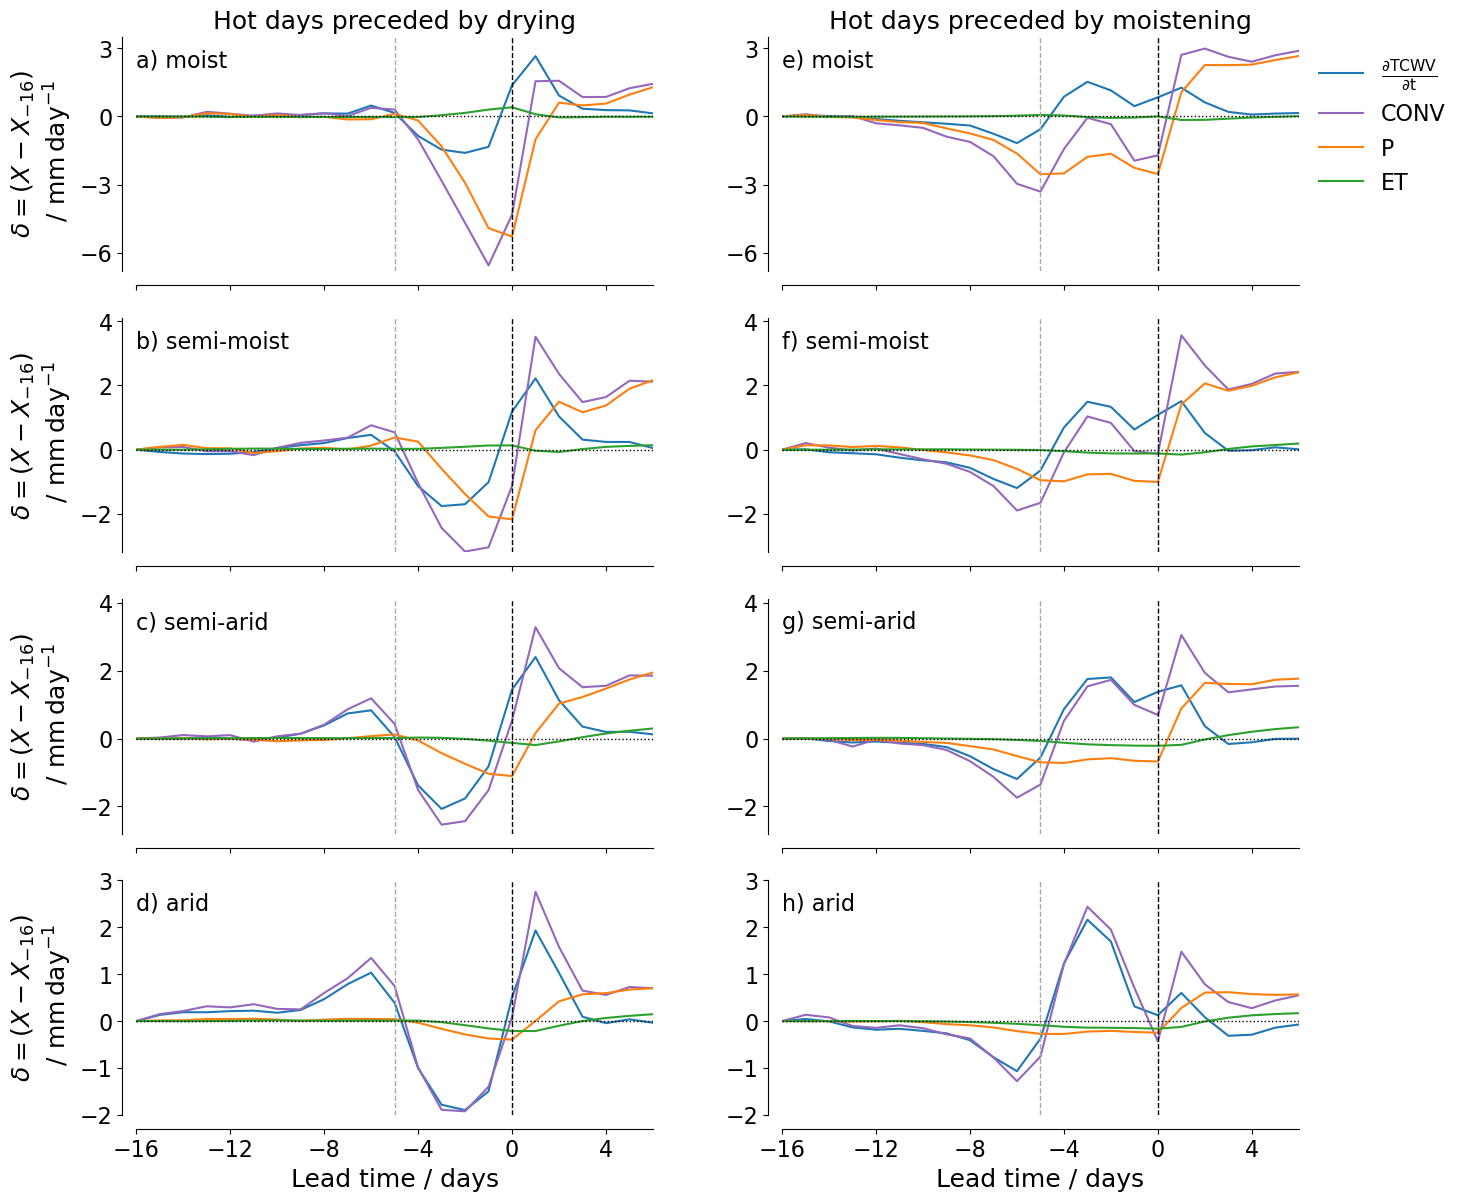

In [ ]:
flux_colors = [var_colors['TCWV'], var_colors['CONV'], var_colors['P'], var_colors['ET']]
flux_names = [r'$\frac{\partial\text{TCWV}}{\partial\text{t}}$', 'CONV', 'P', 'ET']
legend_handles = [Line2D([0], [0], color=c, label=label) for c, label in zip(flux_colors, flux_names)]

fig, ax = plt.subplots(4,2, figsize=(15,14), sharex=True, gridspec_kw={'wspace': 0.25})
lead_time = dmoist_drying.lead_time
ref_time = -16

# plot moisture budget components for drying data subset
data = dmoist_drying
ax[0,0].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time) + (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) - (data.mtpr - data.mtpr.sel(lead_time=ref_time))) * secperday, color=var_colors['TCWV'])
ax[0,0].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[0,0].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[0,0].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

data = dsemimoist_drying
ax[1,0].plot(lead_time, (data.d_tcwv_dt - data.d_tcwv_dt.sel(lead_time=ref_time)), color=var_colors['TCWV'])
ax[1,0].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[1,0].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[1,0].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

data = dsemiarid_drying
ax[2,0].plot(lead_time, (data.d_tcwv_dt - data.d_tcwv_dt.sel(lead_time=ref_time)), color=var_colors['TCWV'])
ax[2,0].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[2,0].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[2,0].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

data = darid_drying
ax[3,0].plot(lead_time, (data.d_tcwv_dt - data.d_tcwv_dt.sel(lead_time=ref_time)), color=var_colors['TCWV'])
ax[3,0].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[3,0].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[3,0].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

# plot moisture budget components for drying data subset
data = dmoist_moistening
ax[0,1].plot(lead_time, (data.d_tcwv_dt - data.d_tcwv_dt.sel(lead_time=ref_time)), color=var_colors['TCWV'])
ax[0,1].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[0,1].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[0,1].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

data = dsemimoist_moistening
ax[1,1].plot(lead_time, (data.d_tcwv_dt - data.d_tcwv_dt.sel(lead_time=ref_time)), color=var_colors['TCWV'])
ax[1,1].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[1,1].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[1,1].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

data = dsemiarid_moistening
ax[2,1].plot(lead_time, (data.d_tcwv_dt - data.d_tcwv_dt.sel(lead_time=ref_time)), color=var_colors['TCWV'])
ax[2,1].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[2,1].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[2,1].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

data = darid_moistening
ax[3,1].plot(lead_time, (data.d_tcwv_dt - data.d_tcwv_dt.sel(lead_time=ref_time)), color=var_colors['TCWV'])
ax[3,1].plot(lead_time, (-data.mvimd + data.mvimd.sel(lead_time=ref_time)) * secperday, color=var_colors['CONV'])
ax[3,1].plot(lead_time, (data.mtpr - data.mtpr.sel(lead_time=ref_time)) * secperday, color=var_colors['P'])
ax[3,1].plot(lead_time, (-data.mer + data.mer.sel(lead_time=ref_time)) * secperday, color=var_colors['ET'])

# set y-axis limits
for a in [ax[0,0], ax[0,1]]:
    a.set_ylim(-6.8,3.5)
    a.set_yticks([-6.0,-3.0, 0, 3.0])
for a in [ax[1,0], ax[1,1]]:
    a.set_ylim(-3.2,4.1)
for a in [ax[2,0], ax[2,1]]:
    a.set_ylim(-2.8,4.1)
for a in [ax[3,0], ax[3,1]]:
    a.set_ylim(-2.0,3.0)

# add zero line for reference
for a in ax.flat:
    a.axhline(0, color='k', linestyle=':', linewidth=1)
    a.axvline(0, color='k', linestyle='dashed', linewidth=1)
    a.axvline(-5, color='darkgray', linestyle = 'dashed', linewidth=1)
    sns.despine(ax=a, offset = 10)
    a.tick_params(axis='both', which='major', labelsize=fs-2)
    a.set_xlim(plot_start, plot_end)
    a.set_xticks([-16, -12, -8, -4, 0, 4])

# set labels, legends and aesthetics
ax[0,0].set_title('Hot days preceded by drying', fontsize=fs)
ax[0,1].set_title('Hot days preceded by moistening', fontsize=fs)
ax[0,0].set_ylabel('$\delta = (X - X_{-16})$\n / mm$\,$day$^{-1}$', fontsize=fs)
ax[1,0].set_ylabel('$\delta = (X - X_{-16})$\n / mm$\,$day$^{-1}$', fontsize=fs)
ax[2,0].set_ylabel('$\delta = (X - X_{-16})$\n / mm$\,$day$^{-1}$', fontsize=fs)
ax[3,0].set_ylabel('$\delta = (X - X_{-16})$\n / mm$\,$day$^{-1}$', fontsize=fs)
ax[3,0].set_xlabel('Lead time / days', fontsize=fs)
ax[3,1].set_xlabel('Lead time / days', fontsize=fs)
ax[0,1].legend(legend_handles, flux_names, frameon=False,fontsize = fs-2, loc='upper left', bbox_to_anchor=(1, 1.), bbox_transform=ax[0,1].transAxes)

# add subplot labels
for i, (a, label) in enumerate(zip([ax[0,0], ax[1,0], ax[2,0], ax[3,0], ax[0,1], ax[1,1], ax[2,1], ax[3,1]], ['a) moist', 'b) semi-moist', 'c) semi-arid', 'd) arid', 'e) moist', 'f) semi-moist', 'g) semi-arid', 'h) arid'])):
    a.text(0, 0.95, label, transform=a.transAxes, ha='left', va='top', fontsize=fs-2)

#plt.savefig(figure_folder + 'full_col_moisture_budget_decomposition_diff_lead16_regime_separation.png', bbox_inches='tight', dpi=300)

## Comparison with climatology

In [24]:
dmoist_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemimoist_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemiarid_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
darid_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')  

dmoist_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemimoist_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
dsemiarid_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')
darid_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc')

<>:58: SyntaxWarning: invalid escape sequence '\D'
<>:59: SyntaxWarning: invalid escape sequence '\D'
<>:60: SyntaxWarning: invalid escape sequence '\D'
<>:58: SyntaxWarning: invalid escape sequence '\D'
<>:59: SyntaxWarning: invalid escape sequence '\D'
<>:60: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_475994/1063513468.py:58: SyntaxWarning: invalid escape sequence '\D'
  ax[1,0].set_ylabel('$\Delta$CONV / mm$\,$day$^{-1}$', fontsize=fs)
/tmp/ipykernel_475994/1063513468.py:59: SyntaxWarning: invalid escape sequence '\D'
  ax[2,0].set_ylabel('$\Delta$P / mm$\,$day$^{-1}$', fontsize=fs)
/tmp/ipykernel_475994/1063513468.py:60: SyntaxWarning: invalid escape sequence '\D'
  ax[3,0].set_ylabel('$\Delta$ET / mm$\,$day$^{-1}$', fontsize=fs)


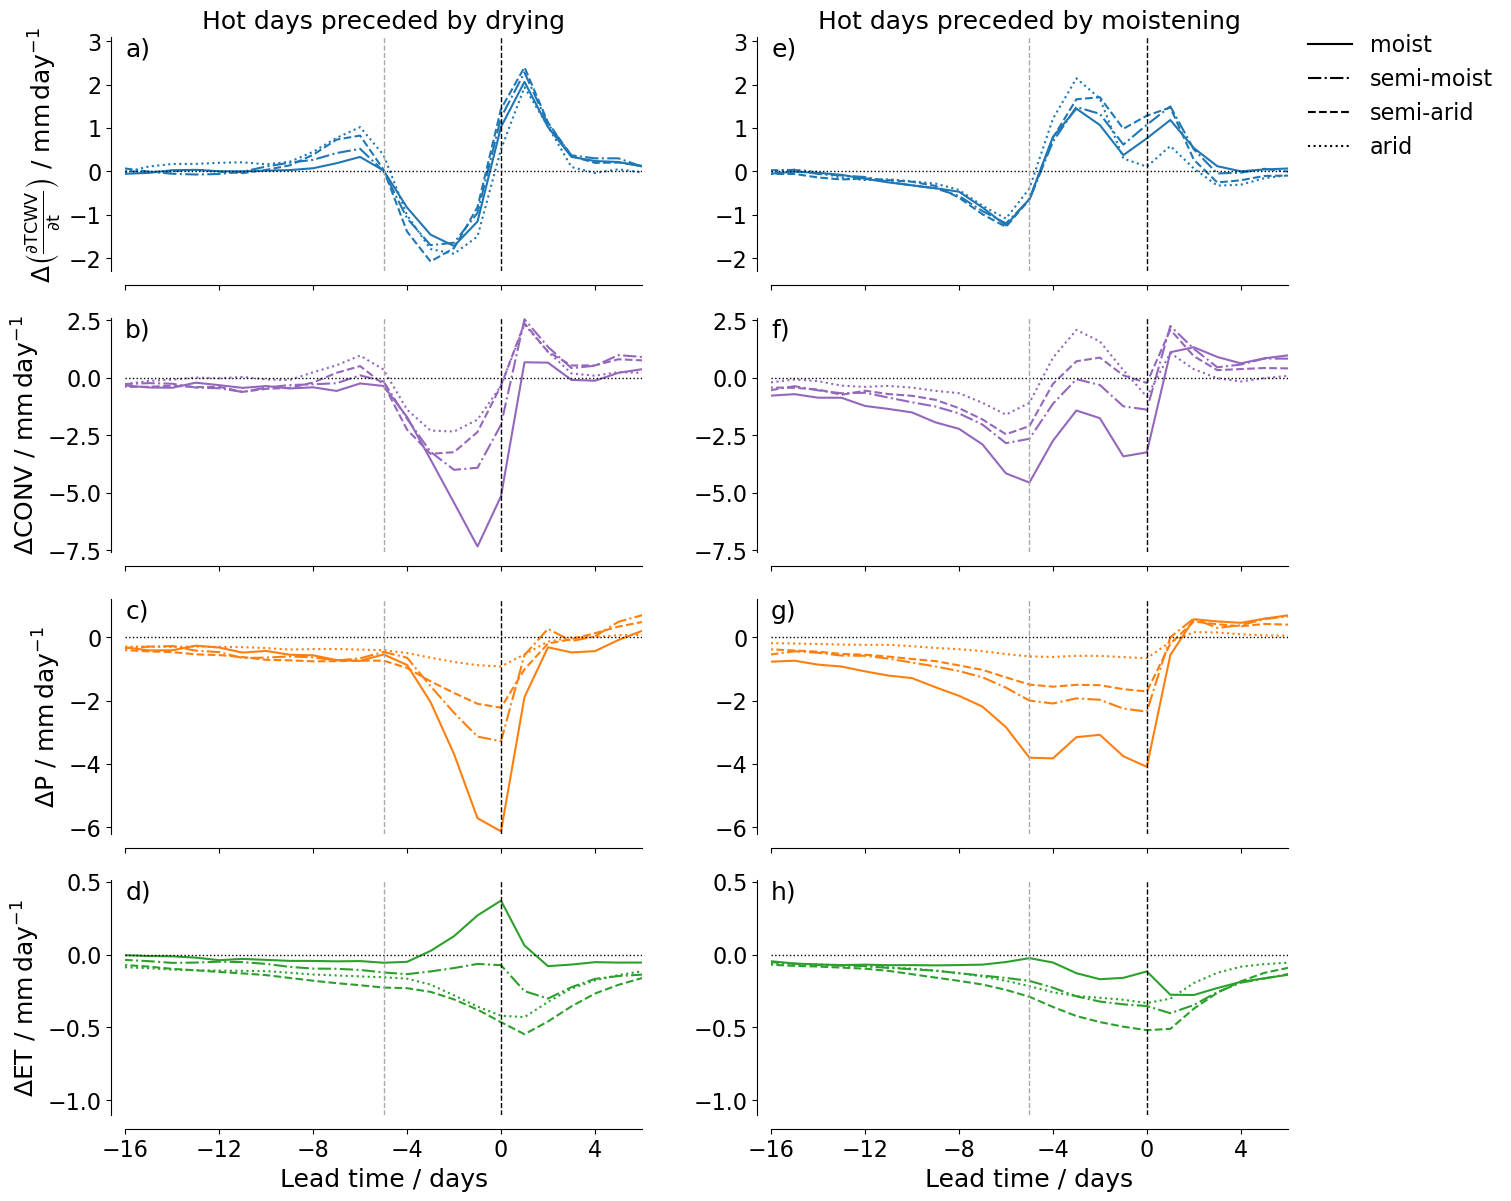

In [ ]:
# same y-axis limits for drying and moistening

legend_handles = [Line2D([0], [0], color='k', linestyle=ls, label=label) for ls, label in zip(aridity_linestyle, aridity_levels_names)]

fig, ax = plt.subplots(4,2, figsize=(15,14), sharex=True, gridspec_kw={'wspace': 0.25})
lead_time = dmoist_drying_clim.lead_time

# plot moisture budget components for drying data subset
for i, (data, label, style) in enumerate(zip(
    [dmoist_drying_clim, dsemimoist_drying_clim, dsemiarid_drying_clim, darid_drying_clim],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,0].plot(lead_time, data.d_tcwv_dt_diff_clim_abs, linestyle=style, color=var_colors['TCWV'])
    ax[1,0].plot(lead_time, -data.mvimd_diff_clim_abs * secperday, linestyle=style, color=var_colors['CONV'])
    ax[2,0].plot(lead_time, data.mtpr_diff_clim_abs * secperday, linestyle=style, color=var_colors['P'])
    ax[3,0].plot(lead_time, -data.mer_diff_clim_abs * secperday, linestyle=style, color=var_colors['ET'])

# plot moisture budget components for moistening data subset
for i, (data, label, style) in enumerate(zip(
    [dmoist_moistening_clim, dsemimoist_moistening_clim, dsemiarid_moistening_clim, darid_moistening_clim],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,1].plot(lead_time, data.d_tcwv_dt_diff_clim_abs, linestyle=style, color=var_colors['TCWV'])
    ax[1,1].plot(lead_time, -data.mvimd_diff_clim_abs * secperday, linestyle=style, color=var_colors['CONV'])
    ax[2,1].plot(lead_time, data.mtpr_diff_clim_abs * secperday, linestyle=style, color=var_colors['P'])
    ax[3,1].plot(lead_time, -data.mer_diff_clim_abs * secperday, linestyle=style, color=var_colors['ET'])

# set y-axis limits
for a in [ax[0,0], ax[0,1]]:
    a.set_ylim(-2.3,3.1)
    a.set_yticks([-2.0,-1.0, 0, 1.0, 2.0, 3.0])
for a in [ax[1,0], ax[1,1]]:
    a.set_ylim(-7.6,2.6)
for a in [ax[2,0], ax[2,1]]:
    a.set_ylim(-6.2,1.2)
for a in [ax[3,0], ax[3,1]]:
    a.set_ylim(-1.1, 0.51)#(-0.62,0.42)
    a.set_xticks([-16, -12, -8, -4, 0, 4])


# add zero line for reference
for a in ax.flat:
    a.axhline(0, color='k', linestyle=':', linewidth=1)
    a.axvline(0, color='k', linestyle='dashed', linewidth=1)
    a.axvline(-5, color='darkgray', linestyle = 'dashed', linewidth=1)
    sns.despine(ax=a, offset = 10)
    a.tick_params(axis='both', which='major', labelsize=fs-2)
    a.set_xlim(plot_start, plot_end)

# set labels, legends and aesthetics
ax[0,0].set_title('Hot days preceded by drying', fontsize=fs)
ax[0,1].set_title('Hot days preceded by moistening', fontsize=fs)
ax[0,1].legend(legend_handles, aridity_levels_names, frameon=False,fontsize = fs-2, loc='upper left', bbox_to_anchor=(1, 1.1), bbox_transform=ax[0,1].transAxes)
#ax[0,0].legend(legend_handles, aridity_levels_names, frameon=False,fontsize = fs-6, bbox_to_anchor=(0.3, 0.4), bbox_transform=ax[0,0].transAxes)
ax[0,0].set_ylabel(r'$\Delta \left(\frac{\partial\text{TCWV}}{\partial\text{t}}\right)$ / mm$\,$day$^{-1}$', fontsize=fs)
ax[1,0].set_ylabel('$\Delta$CONV / mm$\,$day$^{-1}$', fontsize=fs)
ax[2,0].set_ylabel('$\Delta$P / mm$\,$day$^{-1}$', fontsize=fs)
ax[3,0].set_ylabel('$\Delta$ET / mm$\,$day$^{-1}$', fontsize=fs)
ax[3,0].set_xlabel('Lead time / days', fontsize=fs)
ax[3,1].set_xlabel('Lead time / days', fontsize=fs)

# add subplot labels
for i, (a, label) in enumerate(zip([ax[0,0], ax[1,0], ax[2,0], ax[3,0], ax[0,1], ax[1,1], ax[2,1], ax[3,1]], ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)'])):
    a.text(0, 1, label, transform=a.transAxes, ha='left', va='top', fontsize=fs)

#plt.savefig(figure_folder + 'full_col_moisture_budget_decomposition_diff_clim.png', bbox_inches='tight', dpi=300)

# Meteorological variables (Figures 6,8, and 9)

### Met var composites

In [5]:
dmet_moist_drying = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_dmoist_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dmet_semimoist_drying = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_dsemimoist_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dmet_semiarid_drying = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_dsemiarid_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dmet_arid_drying = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_darid_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')  

dmet_moist_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_dmoist_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dmet_semimoist_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_dsemimoist_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dmet_semiarid_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_dsemiarid_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')
dmet_arid_moistening = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/met_vars_darid_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc')


In [6]:
# add evaporative fraction
dmet_moist_drying = dmet_moist_drying.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_dmoist_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)
dmet_semimoist_drying = dmet_semimoist_drying.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_dsemimoist_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)
dmet_semiarid_drying = dmet_semiarid_drying.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_dsemiarid_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)
dmet_arid_drying = dmet_arid_drying.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_darid_drying_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)

dmet_moist_moistening = dmet_moist_moistening.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_dmoist_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)
dmet_semimoist_moistening = dmet_semimoist_moistening.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_dsemimoist_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)
dmet_semiarid_moistening = dmet_semiarid_moistening.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_dsemiarid_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)
dmet_arid_moistening = dmet_arid_moistening.assign(ef = xr.open_dataset(derivatives_folder + composite_folder + 'met_vars/ef_darid_moistening_extreme_var=t2m_dqcrit=' + dq_crit + '_epsilon=0.0.nc').ef)

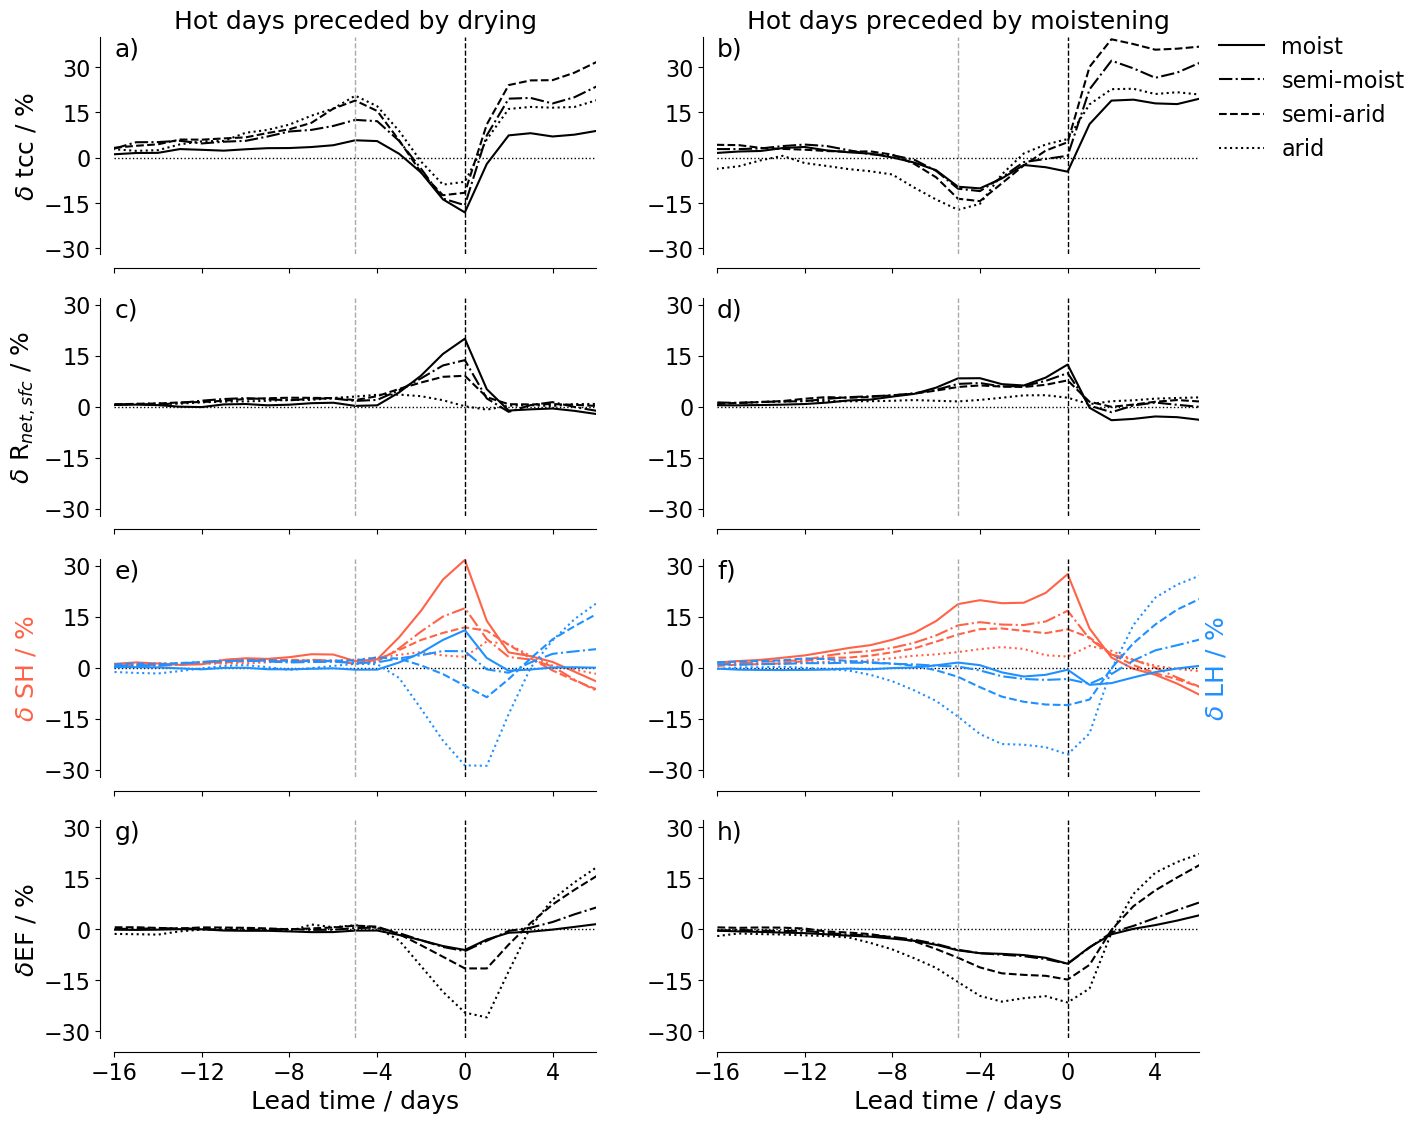

In [ ]:
# fractional changes (except w)
legend_handles = [Line2D([0], [0], color='k', linestyle=ls, label=label) for ls, label in zip(aridity_linestyle, aridity_levels_names)]

fig, ax = plt.subplots(4,2, figsize=(14,13), sharex=True, gridspec_kw={'wspace': 0.25})
lead_time = dmet_moist_drying.lead_time

#define twin axes for SH/LH
lh_ax0 = ax[2,0].twinx()
lh_ax1 = ax[2,1].twinx()
shcol = 'tomato'
lhcol = 'dodgerblue'

# plot moisture budget components for drying data subset
for i, (data, label, style) in enumerate(zip(
    [dmet_moist_drying, dmet_semimoist_drying, dmet_semiarid_drying, dmet_arid_drying],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,0].plot(lead_time, (data.tcc/data.tcc.isel(lead_time=0) - 1) * 100, linestyle=style, color='k')
    ax[1,0].plot(lead_time, ((data.msnlwrf + data.msnswrf) / (data.msnlwrf + data.msnswrf).isel(lead_time=0) - 1) * 100, linestyle=style, color='k')
    ax[2,0].plot(lead_time, ((data.msshf/data.msshf.isel(lead_time=0)) - 1) * 100, linestyle=style, color=shcol)
    lh_ax0.plot(lead_time, ((data.mslhf/data.mslhf.isel(lead_time=0)) - 1) * 100, linestyle=style, color=lhcol)
    ax[3,0].plot(lead_time, (data.ef/data.ef.isel(lead_time=0) - 1) * 100, linestyle=style, color='k')

# plot moisture budget components for moistening data subset
for i, (data, label, style) in enumerate(zip(
    [dmet_moist_moistening, dmet_semimoist_moistening, dmet_semiarid_moistening, dmet_arid_moistening],
    aridity_levels_names,
    aridity_linestyle
)):
    ax[0,1].plot(lead_time, (data.tcc/data.tcc.isel(lead_time=0) - 1) * 100, linestyle=style, color='k')
    ax[1,1].plot(lead_time, ((data.msnlwrf + data.msnswrf) / (data.msnlwrf + data.msnswrf).isel(lead_time=0) - 1) * 100, linestyle=style, color='k')
    ax[2,1].plot(lead_time, ((data.msshf/data.msshf.isel(lead_time=0)) - 1) * 100, linestyle=style, color=shcol)
    lh_ax1.plot(lead_time, ((data.mslhf/data.mslhf.isel(lead_time=0)) - 1) * 100, linestyle=style, color=lhcol)
    ax[3,1].plot(lead_time, (data.ef/data.ef.isel(lead_time=0) - 1) * 100, linestyle=style, color='k')

# set y-axis limits
for a in [ax[1,0], ax[1,1], lh_ax0, lh_ax1, ax[2,0], ax[2,1], ax[3,0], ax[3,1]]:
    a.set_ylim(-32,32)
    a.set_yticks([-30, -15, 0, 15, 30])
for a in [ax[0,0], ax[0,1]]:
    a.set_ylim(-32,40)
    a.set_yticks([-30, -15, 0, 15, 30])
 
for a in ax.flatten():
    a.axvline(0, color='k', linestyle='dashed', linewidth=1)
    a.axvline(-5, color='darkgray', linestyle = 'dashed', linewidth=1)
    a.axhline(0, color='k', linestyle=':', linewidth=1)
    a.set_xlim(plot_start, plot_end)
    a.set_xticks([-16, -12, -8, -4, 0, 4])

# set labels, legends and aesthetics
ax[0,1].legend(legend_handles, aridity_levels_names, frameon=False,fontsize = fs-2, loc='upper left', bbox_to_anchor=(1, 1.1), bbox_transform=ax[0,1].transAxes)
ax[0,0].set_title('Hot days preceded by drying', fontsize=fs)
ax[0,1].set_title('Hot days preceded by moistening', fontsize=fs)
ax[0,0].set_ylabel(r'$\delta$ tcc / %', fontsize=fs)
ax[1,0].set_ylabel(r'$\delta$ R$_{net,sfc}$ / %', fontsize=fs)
ax[2,0].set_ylabel(r'$\delta$ SH / %', color=shcol, fontsize=fs)
lh_ax1.set_ylabel(r'$\delta$ LH / %', color=lhcol, fontsize=fs)
ax[2,0].tick_params(axis='y')
ax[2,1].tick_params(axis='y')
ax[3,0].set_ylabel(r'$\delta$EF / %', fontsize=fs)
ax[3,0].set_xlabel('Lead time / days', fontsize=fs)
ax[3,1].set_xlabel('Lead time / days', fontsize=fs)

# add subplot labels
for i, (a, label) in enumerate(zip([ax[0,0], ax[0,1], ax[1,0], ax[1,1], ax[2,0], ax[2,1], ax[3,0], ax[3,1]], ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)'])): #, 'i)', 'j)'])):
    a.text(0, 1, label, transform=a.transAxes, ha='left', va='top', fontsize=fs)

for a in ax.flat:
    sns.despine(ax=a, offset = 10)
    a.tick_params(axis='both', which='major', labelsize=fs-2)
for a in [lh_ax0, lh_ax1]: #, wblh_ax0, wblh_ax1]:
    sns.despine(ax=a, top=True, left=True, bottom=True, right=True, offset=10)
    a.tick_params(axis='both', which='both', right=False, labelright=False)
#plt.savefig(figure_folder + 'met_var_composites.png', bbox_inches='tight', dpi=300)

### Wave analysis

kelvin  median r = 0.0798   significant: 41% of grid points
wmrg    median r = 0.1307   significant: 64% of grid points
r1      median r = 0.1140   significant: 55% of grid points
r2      median r = 0.0770   significant: 35% of grid points


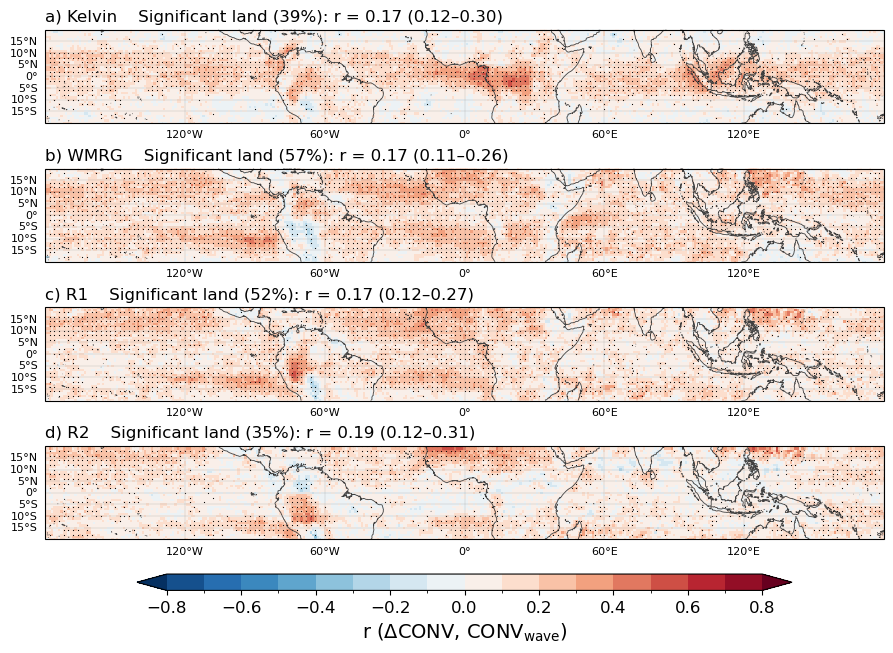

In [10]:
# Correlation with significance test using bootstrapping (mvimd)

"""
Per-grid-point correlation between ERA5's total moisture divergence mvimd (or anomaly, mvimd_anom)
and the moisture flux divergence by each wave type (vimfd), over lead times -12..2 and all years.
Stippling: correlation significantly different from 0 (bootstrap over years, two-sided).
"""
n_boot = 1000          # bootstrap samples
alpha = 0.05               # significance level
use_fdr = True         # control the false discovery rate across grid points (Wilks 2016)
seed = 42
lead_times_sel = slice(-12, 2)
fig_name = f'corr_mvimd_vimfd_waves_with_significance_nboot={n_boot}_alpha={alpha}_fdr=True.png'


def per_year_sums(x, y, dim='lead_time'):
    """Sums over lead times for each year and grid point: n, Σx, Σy, Σx², Σy², Σxy (NaN pairs dropped)."""
    valid = x.notnull() & y.notnull()
    x, y = x.where(valid, 0.0), y.where(valid, 0.0)
    return {'n': valid.sum(dim), 'sx': x.sum(dim), 'sy': y.sum(dim),
            'sxx': (x * x).sum(dim), 'syy': (y * y).sum(dim), 'sxy': (x * y).sum(dim)}


def corr_from_sums(s):
    """Pearson r from summed statistics (works on numpy arrays of any shape)."""
    cov = s['n'] * s['sxy'] - s['sx'] * s['sy']
    var = (s['n'] * s['sxx'] - s['sx'] ** 2) * (s['n'] * s['syy'] - s['sy'] ** 2)
    with np.errstate(invalid='ignore', divide='ignore'):
        return cov / np.sqrt(var)


def bootstrap_corr(x, y, n_boot=n_boot, seed=seed):
    """
    r and two-sided bootstrap p-value at each grid point. Whole events (years, with all their
    lead times) are resampled with replacement; the same resampling is used at every grid point.
    x, y: (lead_time, year, latitude, longitude). Returns r, p as (latitude, longitude).
    """
    # centre each grid point (r is unchanged; avoids round-off in the sums)
    x = (x - x.mean(['lead_time', 'year'])).astype('float64')
    y = (y - y.mean(['lead_time', 'year'])).astype('float64')
    sums = per_year_sums(x, y)
    S = {k: v.transpose('year', ...).values for k, v in sums.items()}        # (year, lat, lon)
    n_year = S['n'].shape[0]

    r = corr_from_sums({k: v.sum(0) for k, v in S.items()})

    # each bootstrap sample = how often each year is drawn (multinomial counts)
    rng = np.random.default_rng(seed)
    counts = rng.multinomial(n_year, np.full(n_year, 1 / n_year), size=n_boot).astype('float64')
    r_boot = corr_from_sums({k: np.einsum('by,y...->b...', counts, v) for k, v in S.items()})

    # two-sided p: how often the bootstrap distribution falls on the other side of 0
    frac_le0 = (r_boot <= 0).mean(0)
    frac_ge0 = (r_boot >= 0).mean(0)
    p = np.clip(2 * np.minimum(frac_le0, frac_ge0), 1 / n_boot, 1)
    p = np.where(np.isfinite(r), p, np.nan)

    coords = {'latitude': x.latitude, 'longitude': x.longitude}
    return (xr.DataArray(r, dims=('latitude', 'longitude'), coords=coords),
            xr.DataArray(p, dims=('latitude', 'longitude'), coords=coords))


def fdr_significant(p, alpha=alpha):
    """Benjamini-Hochberg / Wilks (2016): significant where p <= largest p_(k) with p_(k) <= alpha*k/N."""
    pv = p.values[np.isfinite(p.values)]
    ps = np.sort(pv)
    below = ps <= alpha * np.arange(1, ps.size + 1) / ps.size
    threshold = ps[below].max() if below.any() else 0.0
    return p <= threshold


if __name__ == '__main__':
    dw = xr.open_dataset('/home/users/lucalino/data/era5_wave_data/vimd_data/vimd_wave_hotdays.nc')
    sel = dw.sel(lead_time=lead_times_sel)
    waves = [w for w in sel.wave.values if w != 'era5_full']
    # prepare land-sea mask for correlation range calculation
    # land-sea mask on the 1° grid (0.25° value at each cell centre, as for the dates)
    lsm1 = (dex['lsm'].squeeze(drop=True)
            .sel(latitude=sel.latitude, longitude=sel.longitude, method='nearest', tolerance=1e-3)
            .assign_coords(latitude=sel.latitude, longitude=sel.longitude))
    land = lsm1 > land_thres
    area_weights = np.cos(np.deg2rad(sel.latitude))          # area weights

    results = {}
    for w in waves:
        #r, p = bootstrap_corr(sel.vimfd.sel(wave='era5_full'), sel.vimfd.sel(wave=w)) # vimfd calculated from daily, regridded ERA5 winds
        r, p = bootstrap_corr(sel.mvimd_anom, sel.vimfd.sel(wave=w)) # original but regridded ERA5 variable
        sig = fdr_significant(p) if use_fdr else (p < alpha)
        # quantify correlation range for significant land grid points only
        r_sl = r.where(sig & land)                     
        q_lo, q_med, q_hi = r_sl.weighted(area_weights).quantile([0.1587, 0.5, 0.8413]).values
        share = float(r_sl.notnull().sum() / land.sum())
        results[w] = (r, sig, q_lo, q_med, q_hi, share)
        print(f'{w:7s} median r = {float(r.median()):.4f}   significant: {float(sig.mean()) * 100:.0f}% of grid points')

    levels = np.arange(-0.8, 0.81, 0.1)
    norm = BoundaryNorm(levels, ncolors=256, extend='both')
    names = {'kelvin': 'Kelvin', 'wmrg': 'WMRG', 'r1': 'R1', 'r2': 'R2'}
    fs = 14
    fig, axes = plt.subplots(len(waves), 1, figsize=(11, 1.5 * len(waves) + 0.4), layout='constrained',
                             subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)})

    for i, (ax, w) in enumerate(zip(np.atleast_1d(axes), waves)):
        r, sig, q_lo, q_med, q_hi, share = results[w]
        im = ax.pcolormesh(r.longitude, r.latitude, r, transform=ccrs.PlateCarree(),
                            cmap='RdBu_r', norm=norm, shading='nearest')
        # stipple every second grid point in each direction where significant
        s = sig.isel(latitude=slice(None, None, 2), longitude=slice(None, None, 2))
        lon2d, lat2d = np.meshgrid(s.longitude, s.latitude)
        ax.scatter(lon2d[s.values], lat2d[s.values], s=3, c='k', marker='.', linewidths=0,
                    transform=ccrs.PlateCarree())
        ax.coastlines(linewidth=0.6, color='0.25')
        ax.set_extent([0, 359.99, float(r.latitude.min()), float(r.latitude.max())], crs=ccrs.PlateCarree())
        gl = ax.gridlines(draw_labels=True, linewidth=0.3, color='0.6', alpha=0.6)
        gl.top_labels = gl.right_labels = False
        gl.xlabel_style = gl.ylabel_style = {'size': 8}
        ax.set_title(f'{"abcd"[i]}) {names[w]}    Significant land ({share:.0%}): r = {q_med:.2f} ({q_lo:.2f}–{q_hi:.2f})', loc='left', fontsize=fs-2)
        #ax.set_title(f'{w}    median r = {float(q_med):.2f} ({q_lo:.2f}–{q_hi:.2f})', loc='left', fontsize=fs-2)

    lt = sel.lead_time.values
    test = f'FDR {alpha}' if use_fdr else f'p < {alpha}'
    cbar = fig.colorbar(im, ax=axes, location='bottom', shrink=0.6, aspect=40, pad=0.03)
    cbar.set_label(r'r ($\Delta$CONV, CONV$_\mathrm{wave}$)', fontsize=fs) 
    cbar.ax.tick_params(labelsize=fs-2) 
    #fig.suptitle(f'Correlation over lead times {lt.min()} to {lt.max()} days and {sel.sizes["year"]} years;\n '
    #             f'dots: significant ({test}, bootstrap over years, n = {n_boot})', fontsize=fs)
    fig.savefig(figure_folder + fig_name, dpi=250, bbox_inches='tight', pad_inches=0.05)


<>:43: SyntaxWarning: invalid escape sequence '\D'
<>:43: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_475994/2343171297.py:43: SyntaxWarning: invalid escape sequence '\D'
  ax.set_ylabel('$\Delta$CONV$_{\mathrm{(wave)}}$ / mm$\,$day$^{-1}$', fontsize=fs)


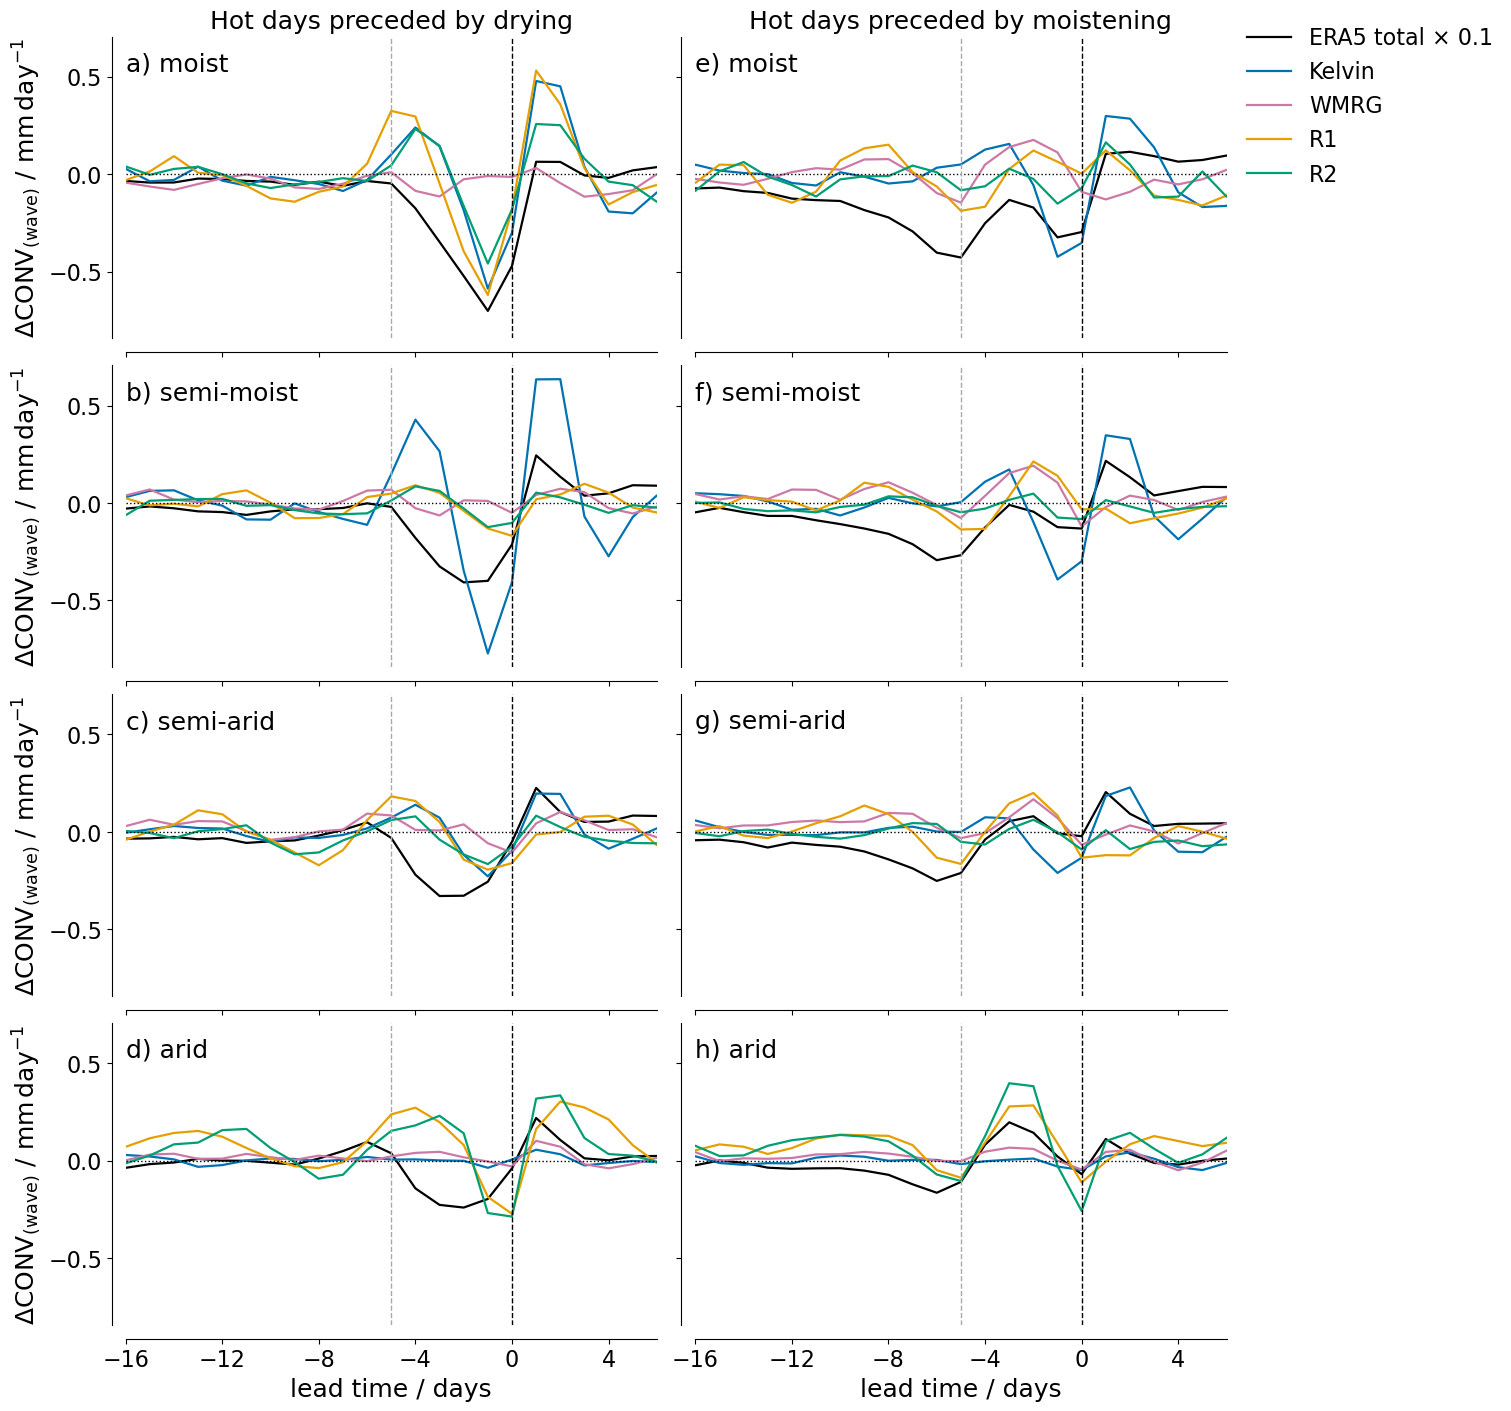

In [ ]:
# composite timeseries
wave_composite_folder = "/home/users/lucalino/data/era5_wave_data/vimd_data/composites/"
fig_name = 'wave_conv_composite_timeseries.png'

regimes = ['moist', 'semimoist', 'semiarid', 'arid']
event_types = ['drying', 'moistening']
lw = 1.6

era5_scale = 0.1    # choose so that the ERA5 curve has a similar height to the waves

# fixed colour and line style per wave (line styles keep the waves apart for colour-blind readers and in print)
wave_style = {
    'kelvin': dict(color='#0072B2', linestyle='-'),
    'wmrg':   dict(color='#CC79A7', linestyle='-'),
    'r1':     dict(color='#E69F00', linestyle='-'),
    'r2':     dict(color='#009E73', linestyle='-'),
}

wave_name = {
    'kelvin': 'Kelvin',
    'wmrg':   'WMRG',
    'r1':     'R1',
    'r2':     'R2'
}

fig, axes = plt.subplots(len(regimes), len(event_types), figsize=(15, 14), sharex=True, sharey=True, layout='constrained')

for row, regime in enumerate(regimes):
    for col, t in enumerate(event_types):
        ax = axes[row, col]
        c = xr.open_dataset(wave_composite_folder + f'd{regime}_{t}_vimd_wave_composite.nc')
        mbc = xr.open_dataset(derivatives_folder + composite_folder + f'full_col_d{regime}_{t}_dqcrit=' + dq_crit + '_epsilon=0.0.nc')[['mtpr', 'mer']]

        ax.plot(c.lead_time, -c['mvimd_anom'] * secperday * era5_scale, color='black', linewidth=lw,
                label=f'ERA5 total × {era5_scale}')
        
        for w, style in wave_style.items():
            ax.plot(c.lead_time, -c['vimfd'].sel(wave=w) * secperday, linewidth=lw, label=wave_name.get(w, w), **style)

        if row == len(regimes) - 1:
            ax.set_xlabel('lead time / days', fontsize=fs)
        if col == 0:
            ax.set_ylabel('$\Delta$CONV$_{\mathrm{(wave)}}$ / mm$\,$day$^{-1}$', fontsize=fs)
for a in axes.flatten():
    a.set_xlim(plot_start, plot_end)
    a.set_xticks([-16, -12, -8, -4, 0, 4])
    a.set_yticks([-0.5, 0, 0.5])
    a.axhline(0, color='k', linestyle=':', linewidth=1)
    a.axvline(0, color='k', linestyle='dashed', linewidth=1)
    a.axvline(-5, color='darkgray', linestyle = 'dashed', linewidth=1)
    a.tick_params(axis='both', which='major', labelsize=fs-2)

axes[0,0].set_title('Hot days preceded by drying', fontsize=fs)
axes[0,1].set_title('Hot days preceded by moistening', fontsize=fs)

# add subplot labels
for i, (a, label) in enumerate(zip([axes[0,0], axes[1,0], axes[2,0], axes[3,0], axes[0,1], axes[1,1], axes[2,1], axes[3,1]], ['a) moist', 'b) semi-moist', 'c) semi-arid', 'd) arid', 'e) moist', 'f) semi-moist', 'g) semi-arid', 'h) arid'])):
    a.text(0, 0.95, label, transform=a.transAxes, ha='left', va='top', fontsize=fs)

handles, labels = axes[0, 0].get_legend_handles_labels()
sns.despine(offset=10)
axes[0,1].legend(handles, labels, frameon=False,fontsize = fs-2, loc='upper left', bbox_to_anchor=(1, 1.1), bbox_transform=axes[0,1].transAxes)
#fig.savefig(figure_folder + fig_name, dpi=250)
plt.show()

# Aridity-independence of TCWV changes (Figure 10)

In [13]:
lead_time_slice = slice(-16,6)
dmoist_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)
dsemimoist_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)
dsemiarid_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)
darid_drying_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_drying_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)

dmoist_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dmoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)
dsemimoist_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemimoist_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)
dsemiarid_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_dsemiarid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)
darid_moistening_clim = xr.open_dataset(derivatives_folder + composite_folder + 'full_col_darid_moistening_dqcrit=' + dq_crit + '_epsilon=0.0_doy_clim_comparison.nc').sel(lead_time = lead_time_slice)

### Aridity-independence figure from climatological anomalies

In [14]:
# combine moistening and drying for better sample size
DeltaCONV_moist = np.append(dmoist_drying_clim.mvimd_diff_clim_abs.values, dmoist_moistening_clim.mvimd_diff_clim_abs.values)
DeltaCONV_semimoist = np.append(dsemimoist_drying_clim.mvimd_diff_clim_abs.values, dsemimoist_moistening_clim.mvimd_diff_clim_abs.values)
DeltaCONV_semiarid = np.append(dsemiarid_drying_clim.mvimd_diff_clim_abs.values, dsemiarid_moistening_clim.mvimd_diff_clim_abs.values)
DeltaCONV_arid = np.append(darid_drying_clim.mvimd_diff_clim_abs.values, darid_moistening_clim.mvimd_diff_clim_abs.values)

DeltaP_moist = np.append(dmoist_drying_clim.mtpr_diff_clim_abs.values, dmoist_moistening_clim.mtpr_diff_clim_abs.values)
DeltaP_semimoist = np.append(dsemimoist_drying_clim.mtpr_diff_clim_abs.values, dsemimoist_moistening_clim.mtpr_diff_clim_abs.values)
DeltaP_semiarid = np.append(dsemiarid_drying_clim.mtpr_diff_clim_abs.values, dsemiarid_moistening_clim.mtpr_diff_clim_abs.values)
DeltaP_arid = np.append(darid_drying_clim.mtpr_diff_clim_abs.values, darid_moistening_clim.mtpr_diff_clim_abs.values)

DeltaET_moist = np.append(dmoist_drying_clim.mer_diff_clim_abs.values, dmoist_moistening_clim.mer_diff_clim_abs.values)
DeltaET_semimoist = np.append(dsemimoist_drying_clim.mer_diff_clim_abs.values, dsemimoist_moistening_clim.mer_diff_clim_abs.values)
DeltaET_semiarid = np.append(dsemiarid_drying_clim.mer_diff_clim_abs.values, dsemiarid_moistening_clim.mer_diff_clim_abs.values)
DeltaET_arid = np.append(darid_drying_clim.mer_diff_clim_abs.values, darid_moistening_clim.mer_diff_clim_abs.values)

In [15]:
dc_all = [DeltaCONV_moist, DeltaCONV_semimoist, DeltaCONV_semiarid, DeltaCONV_arid]
dp_all = [DeltaP_moist, DeltaP_semimoist, DeltaP_semiarid, DeltaP_arid]
det_all = [DeltaET_moist, DeltaET_semimoist, DeltaET_semiarid, DeltaET_arid]
epsilon_names = [r'$\epsilon_{\text{moist}}$', r'$\epsilon_{\text{semi-moist}}$', r'$\epsilon_{\text{semi-arid}}$', r'$\epsilon_{\text{arid}}$']

moist: r =  0.9
semi-moist: r =  0.76
semi-arid: r =  0.5
arid: r =  0.27


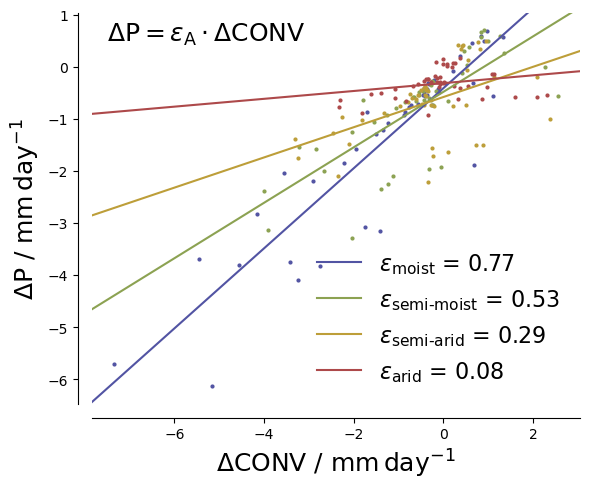

In [18]:
fig, ax = plt.subplots(figsize=(6,5))
for i in range(0,4):
    dc = (-1) * dc_all[i] * secperday
    dp = dp_all[i] * secperday
    ax.scatter(dc, dp, color = ai_palette[aridity_levels_names[i]], s = 4)
    r, p = np.round(pearsonr(dc, dp),2)
    print(aridity_levels_names[i] + ': r = ', np.round(r, 2))
    m, b = np.polyfit(dc, dp, 1)
    ax.axline(xy1=(0, b), slope=m, color = ai_palette[aridity_levels_names[i]], label=epsilon_names[i] + f' = {m:.2f}')
ax.set_ylabel(r'$\Delta$P / mm$\,$day$^{-1}$', fontsize = fs)
ax.set_xlabel(r'$\Delta$CONV / mm$\,$day$^{-1}$', fontsize = fs)
ax.legend(loc='lower right', frameon=False, fontsize = fs-2)
ax.text(-7.5, 0.5, r'$\Delta\text{P} = \epsilon_\text{A} \cdot \Delta\text{CONV}$', fontsize =fs)
sns.despine(offset=10)
plt.tight_layout()
plt.savefig(figure_folder + 'epsilon_from_composite_dP_vs_dCONV_drying+moistening.jpg', dpi=200)

In [5]:
# recreating the above figure from grid cell level data (array entries already multiplied by secperday, and (-1) for convergence)
DeltaP_moist_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mtpr_diff_clim_abs_moist_land_extreme_var={extreme_var}.npy')
DeltaP_semimoist_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mtpr_diff_clim_abs_semimoist_land_extreme_var={extreme_var}.npy')
DeltaP_semiarid_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mtpr_diff_clim_abs_semiarid_land_extreme_var={extreme_var}.npy')
DeltaP_arid_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mtpr_diff_clim_abs_arid_land_extreme_var={extreme_var}.npy')

DeltaCONV_moist_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mvimd_diff_clim_abs_moist_land_extreme_var={extreme_var}.npy')
DeltaCONV_semimoist_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mvimd_diff_clim_abs_semimoist_land_extreme_var={extreme_var}.npy')
DeltaCONV_semiarid_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mvimd_diff_clim_abs_semiarid_land_extreme_var={extreme_var}.npy')
DeltaCONV_arid_gc = np.load(derivatives_folder + f'clim_diff_arrays/era5_hot_day_mvimd_diff_clim_abs_arid_land_extreme_var={extreme_var}.npy')

dc_all_gc = [DeltaCONV_moist_gc, DeltaCONV_semimoist_gc, DeltaCONV_semiarid_gc, DeltaCONV_arid_gc]
dp_all_gc = [DeltaP_moist_gc, DeltaP_semimoist_gc, DeltaP_semiarid_gc, DeltaP_arid_gc]

epsilon_names = [r'$\epsilon_{\text{moist}}$', r'$\epsilon_{\text{semi-moist}}$', r'$\epsilon_{\text{semi-arid}}$', r'$\epsilon_{\text{arid}}$']

moist: r =  0.88
semi-moist: r =  0.69
semi-arid: r =  0.53
arid: r =  0.32


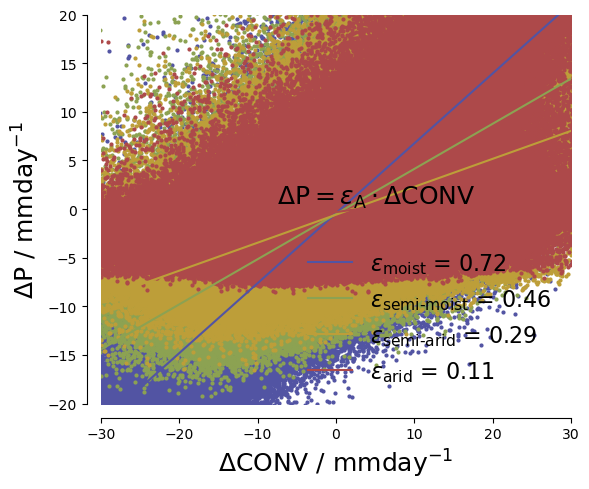

In [19]:
fig, ax = plt.subplots(figsize=(6,5))
for i in range(0,4):
    dc = dc_all_gc[i]
    dp = dp_all_gc[i]
    ax.scatter(dc, dp, color = ai_palette[aridity_levels_names[i]], s = 4)
    r, p = np.round(pearsonr(dc, dp),2)
    print(aridity_levels_names[i] + ': r = ', np.round(r, 2))
    m, b = np.polyfit(dc, dp, 1)
    ax.axline(xy1=(0, b), slope=m, color = ai_palette[aridity_levels_names[i]], label=epsilon_names[i] + f' = {m:.2f}')
ax.set_xlim(-30, 30)
ax.set_ylim(-20, 20)
ax.set_ylabel(r'$\Delta$P / mmday$^{-1}$', fontsize = fs)
ax.set_xlabel(r'$\Delta$CONV / mmday$^{-1}$', fontsize = fs)
ax.legend(loc='lower right', frameon=False, fontsize = fs-2)
ax.text(-7.5, 0.5, r'$\Delta\text{P} = \epsilon_\text{A} \cdot \Delta\text{CONV}$', fontsize =fs)
sns.despine(offset=10)
plt.tight_layout()
#plt.savefig(figure_folder + 'epsilon_from_composite_dP_vs_dCONV_drying+moistening.jpg', dpi=200)